# 04. Feature Engineering & Modeling
## Home Credit Default Risk: Credit Scoring Model

Notebook ini membangun model untuk memprediksi **probabilitas gagal bayar (PD)** setiap pemohon, lalu mengukur dampaknya terhadap metrik bisnis NB 01.

**Prinsip kerja:**
1. **Setiap keputusan punya alasan, terhubung ke temuan EDA (NB 03) dan, bila ada, sumber literatur.** Ringkasannya di Bagian 0.
2. **Tidak ada kebocoran data.** Data test (20%) hanya dibuka sekali di akhir; semua pemilihan (fitur, preprocessing, hyperparameter, class weight, threshold) memakai cross-validation di data train. Semua langkah yang "belajar" dari data (imputasi, scaling, encoding) berada di dalam **satu pipeline** yang dilatih ulang di setiap fold.
3. **Metrik mengikuti NB 01:** PR curve / PR-AUC untuk memilih model; **F2-score** sebagai metrik utama klasifikasi untuk memilih threshold, dengan **guardrail biaya** (total biaya tidak boleh lebih buruk dari tanpa model).

## 0. Ringkasan Keputusan

| # | Keputusan | Pilihan | Alasan | Sumber |
|---|---|---|---|---|
| 1 | Jenis masalah | Klasifikasi biner, output probabilitas | `TARGET` 0/1; bisnis butuh skor risiko | NB 01 |
| 2 | Data | Data mart **versi 2** (riwayat 12 bulan terakhir, beban utang, status pengajuan terakhir) | Versi 1 hanya rata-rata sepanjang masa; perilaku terbaru lebih prediktif | NB 02 Bagian 8.2; Siddiqi (2017) |
| 3 | Audit kebocoran | Cek waktu semua tabel riwayat + cek fitur yang "terlalu bagus" | Fitur dari masa setelah pengajuan = *target leakage* | Kaufman et al. (2012) |
| 4 | Pembagian data | **80% train / 20% test**, stratified | 20% = ±61.500 nasabah (±5.000 gagal bayar), cukup untuk estimasi stabil | Raschka (2018) |
| 5 | Validasi | Stratified **3-fold CV** di train | Setiap fold validasi ±82.000 nasabah, variansi estimasi sudah kecil | Kohavi (1995) |
| 6 | Seleksi fitur | Berbasis **domain + hasil uji statistik NB 03** (redundan, hampir konstan, atribut proses, gender) | Fitur dibuang hanya bila ada alasan jelas; filter IV tidak dipakai karena terbukti menurunkan performa model pohon (run versi 1) | NB 03 Bagian 3.5-3.7; POJK 22/2023 |
| 7 | Nilai kosong | **Median + kolom penanda kosong** (angka); kategori **"Missing"** | Median tahan terhadap data menceng; kekosongan itu sendiri informatif (NB 03 Q14) | Little & Rubin (2019) |
| 8 | Outlier | **Winsorizing persentil 1-99** (dipelajari dari train) | Tidak membuang nasabah, hanya membatasi pengaruh nilai ekstrem (pendapatan maks 248× p99, NB 03 Bagian 2.3) | NB 03 |
| 9 | Transformasi & scaling | Menceng ≥ 0: **log1p + StandardScaler**; menceng bisa negatif: **RobustScaler**; simetris: **StandardScaler**; biner: **passthrough** | Sesuai bentuk distribusi masing-masing kolom (skewness, NB 03 Bagian 3.1) | Kuhn & Johnson (2019) |
| 10 | Encoding kategori | ≤ 10 kategori: **one-hot**; > 10 kategori: **target encoding** (cross-fitted); pendidikan: **ordinal** | One-hot untuk kardinalitas rendah; target encoding untuk kardinalitas tinggi tanpa ledakan kolom dan tanpa urutan palsu seperti binary encoder | Micci-Barreca (2001); Pargent et al. (2022) |
| 11 | Pipeline | **Satu ColumnTransformer untuk semua model** | Konsisten dan mudah dipakai Streamlit; model pohon tidak terpengaruh transformasi monoton (diverifikasi di Eksperimen 0) | Dokumentasi scikit-learn |
| 12 | Model | Dummy, **Logistic Regression**, Random Forest, LightGBM, XGBoost, + uji ensemble | LogReg = standar scorecard & wajib di tugas; tiga ensemble pohon terkuat untuk data tabular | Siddiqi (2017); Breiman (2001); Ke et al. (2017); Chen & Guestrin (2016) |
| 13 | Imbalance | Diuji: dengan vs tanpa class weight | Class weight bisa merusak kalibrasi tanpa menaikkan kemampuan ranking | van den Goorbergh et al. (2022) |
| 14 | Tuning | RandomizedSearchCV, scoring **PR-AUC**, ruang parameter luas **termasuk parameter preprocessing** | Random search efisien untuk banyak parameter | Bergstra & Bengio (2012) |
| 15 | Threshold | **F2 maksimum dengan guardrail total biaya ≤ tanpa model** (LGD 45%) | F2 metrik utama (NB 01), tetapi F2 tidak menghitung nilai nasabah baik yang disetujui | Elkan (2001); NB 01 |
| 16 | Interpretasi | SHAP | Penjelasan global & per nasabah | Lundberg & Lee (2017) |

## 1. Setup

In [11]:
import warnings
warnings.filterwarnings('ignore')

import os, sys, time, json, joblib
from pathlib import Path

# Cari folder proyek (yang berisi src/features.py) dari folder kerja saat ini ke atas
_here = Path.cwd()
PROJECT_DIR = next(p for p in [_here, *_here.parents] if (p / 'src' / 'features.py').exists())
os.chdir(PROJECT_DIR); sys.path.insert(0, str(PROJECT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             confusion_matrix, brier_score_loss, fbeta_score, precision_score, recall_score)
from sklearn.calibration import calibration_curve
from scipy.stats import loguniform, ks_2samp
import lightgbm as lgb
import xgboost as xgb
import shap
from src.features import (load_mart, clean_and_engineer, domain_drop_columns, column_groups, build_preprocessor,
                          ColumnSelector, ToCategory)

SEED, N_JOBS = 42, -1
PROCESSED_DIR = Path('data/processed'); MODEL_DIR = Path('models'); MODEL_DIR.mkdir(exist_ok=True)

NAVY, RED, BLUE, GREEN, ORANGE, INK, MUTED = '#1F3A5F', '#C8553D', '#4A7BA6', '#3E8E6E', '#D9A441', '#2B2B2B', '#7A7A7A'
MODEL_COLORS = {'Dummy': MUTED, 'Logistic Regression': BLUE, 'Random Forest': GREEN, 'LightGBM': RED, 'XGBoost': ORANGE, 'Ensemble': NAVY}
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'font.size': 10, 'text.color': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 22,
    'axes.labelcolor': INK, 'axes.edgecolor': '#BFBFBF', 'axes.grid': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
fmt = lambda v, d=1: f'{v:,.{d}f}'.replace(',', '#').replace('.', ',').replace('#', '.')
def subtitle(ax, text): ax.text(0, 1.02, text, transform=ax.transAxes, fontsize=9.5, color=MUTED, va='bottom')
def finish(): plt.tight_layout(); plt.show()
print('Folder proyek:', PROJECT_DIR)
print('LightGBM', lgb.__version__, '| XGBoost', xgb.__version__, '| SHAP', shap.__version__)

Folder proyek: c:\Users\LOQ\Downloads\home-credit-project
LightGBM 4.7.0 | XGBoost 3.4.1 | SHAP 0.53.0


## 2. Audit Kebocoran Data (*Leakage*)

Kebocoran terjadi jika model memakai informasi yang **belum tersedia saat pengajuan**, sehingga performanya terlihat bagus saat uji tetapi gagal di dunia nyata.

### 2.1 Audit waktu tabel riwayat
Semua kolom waktu bersifat relatif terhadap tanggal pengajuan (negatif = sebelum pengajuan). Dicek langsung di tabel mentah (NB 02):

| Tabel / kolom | Nilai maksimum | Status | Keputusan |
|---|---|---|---|
| `installments_payments.DAYS_INSTALMENT` / `DAYS_ENTRY_PAYMENT` | -1 | Aman (semua sebelum pengajuan) | Dipakai |
| `POS_CASH_balance.MONTHS_BALANCE`, `credit_card_balance.MONTHS_BALANCE` | -1 | Aman | Dipakai |
| `bureau_balance.MONTHS_BALANCE` | 0 | Aman (bulan pengajuan) | Dipakai |
| `previous_application.DAYS_DECISION` | -1 | Aman | Dipakai |
| `bureau.DAYS_CREDIT_UPDATE` | **+372** (17 baris) | **Berisiko**: informasi diperbarui setelah pengajuan | **Tidak dipakai** |
| `bureau.DAYS_CREDIT_ENDDATE` | +31.199 | Aman: tanggal jatuh tempo kontrak sudah diketahui saat pengajuan | Dipakai (rata-rata) |
| `previous_application.DAYS_LAST_DUE_1ST_VERSION` | 365243 (93.864 baris) | Kode sistem "tidak ada tanggal", bukan kebocoran | Dianggap kosong di query v2 |

### 2.2 Cek fitur yang "terlalu bagus"
Satu fitur dengan ROC-AUC tunggal > 0,70 patut dicurigai, karena gagal bayar tidak mungkin ditentukan oleh satu informasi saja. Dihitung setelah pembagian data (Bagian 4), di data train saja.

## 3. Cleaning & Feature Engineering

Fungsi `clean_and_engineer` (di `src/features.py`) dipakai bersama oleh notebook ini dan aplikasi Streamlit. Semua langkahnya **per-baris** (tidak belajar dari data), sehingga aman sebelum split.

**Cleaning** (NB 03 Bagian 2.6): `DAYS_EMPLOYED = 365243` menjadi kosong + `IS_NOT_EMPLOYED`; `CODE_GENDER = XNA` dan `NAME_FAMILY_STATUS = Unknown` menjadi kosong; `ORGANIZATION_TYPE = XNA` menjadi `Not employed`; jumlah riwayat kosong diisi 0 + penanda `HAS_BUREAU`, `HAS_PREV`, `HAS_CC`.

**Feature engineering**: hanya fitur yang punya **dasar temuan EDA / uji statistik** dan **makna bisnis** yang jelas bagi analis kredit:

| Fitur | Rumus | Dasar (NB 03) | Makna bisnis |
|---|---|---|---|
| `EXT_SOURCE_MEAN`, `EXT_SOURCE_MIN`, `EXT_SOURCE_NA_CNT` | Rata-rata, minimum, jumlah skor eksternal kosong | Q1-Q2; IV tertinggi (0,61); effect size Mann-Whitney tertinggi | Ringkasan penilaian lembaga lain; skor kosong = *thin-file* |
| `AGE_YEARS` | Hari lahir menjadi tahun | Q3-Q4 | Usia pemohon |
| `EMPLOYED_YEARS`, `EMPLOYED_TO_AGE`, `IS_NOT_EMPLOYED` | Lama kerja; proporsi hidup bekerja | Q7; Mann-Whitney signifikan | Stabilitas pekerjaan |
| `ANNUITY_INCOME` | Cicilan / pendapatan | Q5 (lemah tapi signifikan) | *Debt service ratio* |
| `CREDIT_GOODS`, `HAS_DOWN_PAYMENT` | Pinjaman / harga barang; ada uang muka? | Q6; Mann-Whitney peringkat 7 | Uang muka = nasabah ikut menanggung risiko |
| `CREDIT_INCOME`, `CREDIT_TERM`, `INCOME_PER_PERSON` | Pinjaman / pendapatan; perkiraan tenor; pendapatan per anggota keluarga | Kemampuan bayar (5C: *Capacity*) | Besar pinjaman relatif, lama cicilan, beban tanggungan |
| `BUREAU_DEBT_INCOME` | Utang aktif di lembaga lain / pendapatan | Q12 | Total beban utang di luar Home Credit |
| `PHONE_CHANGE_YEARS`, `REGISTRATION_YEARS`, `ID_PUBLISH_YEARS`, `ADDRESS_MISMATCH_CNT` | Lama sejak ganti HP / alamat / KTP; jumlah ketidaksesuaian alamat | Q10; Mann-Whitney signifikan | Stabilitas & kemudahan penagihan |
| `DOC_COUNT` | Jumlah dokumen diserahkan | Ringkasan 20 kolom ber-IV < 0,02 | Kelengkapan dokumen |
| Fitur riwayat v2 (`INST_*`, `BUREAU_*`, `PREV_*`, `POS_*`, `CC_*`) | Agregasi SQL di BigQuery | Q11-Q13 | Perilaku bayar & beban utang terbaru |

In [12]:
raw      = load_mart(PROCESSED_DIR / 'mart_v2_train.parquet')
test_raw = load_mart(PROCESSED_DIR / 'mart_v2_test.parquet')
data        = clean_and_engineer(raw)
kaggle_test = clean_and_engineer(test_raw)
X_all = data.drop(columns=['SK_ID_CURR', 'TARGET']); y_all = data['TARGET'].astype(int)
print(f'Setelah cleaning & feature engineering: {X_all.shape[0]:,} nasabah × {X_all.shape[1]} kolom')

Setelah cleaning & feature engineering: 307,511 nasabah × 200 kolom


## 4. Pembagian Data: Train 80% / Test 20%

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
pd.DataFrame({'jumlah_nasabah': [len(y_train), len(y_test)], 'jumlah_gagal_bayar': [y_train.sum(), y_test.sum()],
              'default_rate_%': [y_train.mean() * 100, y_test.mean() * 100]}, index=['Train (80%)', 'Test (20%)']).round(2)

,jumlah_nasabah,jumlah_gagal_bayar,default_rate_%
Train (80%),246008,19860,8.07
Test (20%),61503,4965,8.07


**Cara membaca:** default rate train dan test sama (8,07%) karena pembagian *stratified*. Data test dikunci sampai Bagian 14.

In [14]:
# Lanjutan audit 2.2: ROC-AUC satu fitur, dihitung di data train saja
single_auc = {}
for c in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[c]) and X_train[c].nunique() > 1:
        a = roc_auc_score(y_train, X_train[c].fillna(X_train[c].median())); single_auc[c] = max(a, 1 - a)
single_auc = pd.Series(single_auc).sort_values(ascending=False)
print(f'Fitur dengan ROC-AUC tunggal > 0,70 (dicurigai bocor): {(single_auc > 0.70).sum()}')
single_auc.head(8).round(3).to_frame('ROC-AUC satu fitur')

Fitur dengan ROC-AUC tunggal > 0,70 (dicurigai bocor): 1


,ROC-AUC satu fitur
EXT_SOURCE_MEAN,0.716
EXT_SOURCE_MIN,0.690
EXT_SOURCE_2,0.656
EXT_SOURCE_3,0.649
BUREAU_DAYS_CREDIT_MEAN,0.589
AGE_YEARS,0.583
EXT_SOURCE_1,0.582
EMPLOYED_YEARS,0.579


**Hasil:** hanya `EXT_SOURCE_MEAN` yang melewati 0,70 (±0,72), disusul `EXT_SOURCE_MIN` (±0,69), `EXT_SOURCE_2` dan `EXT_SOURCE_3` (±0,65). Ini **bukan kebocoran**: skor eksternal berasal dari lembaga lain **sebelum** pengajuan, dan temuan ini konsisten dengan NB 03 (IV tertinggi, effect size tertinggi). Fitur riwayat teratas hanya ±0,59, sehingga tidak ada fitur riwayat yang mencurigakan.

## 5. Seleksi Fitur Berbasis Domain

Kolom dibuang **hanya jika ada alasan jelas** dari uji statistik NB 03 atau pertimbangan bisnis. Sisanya dipilih oleh model sendiri melalui regularisasi (LogReg) atau mekanisme split (model pohon).

In [15]:
drop_reasons = domain_drop_columns(X_train.columns)
FEATURES = [c for c in X_train.columns if c not in drop_reasons]
dr = pd.Series(drop_reasons).rename('alasan').to_frame()
dr['kelompok_alasan'] = dr.alasan.str.split(':').str[0]
print(f'Kolom awal: {X_train.shape[1]}  |  dibuang: {len(dr)}  |  dipakai: {len(FEATURES)}')
dr.groupby('kelompok_alasan').agg(jumlah_kolom=('alasan', 'size'), alasan=('alasan', 'first'), contoh=('alasan', lambda s: ', '.join(s.index[:3])))

Kolom awal: 200  |  dibuang: 58  |  dipakai: 142


,jumlah_kolom,alasan,contoh
kelompok_alasan,,,
"Atribut proses pengajuan, bukan profil kelayakan kredit; rawan berubah jika proses operasional berubah",2,"Atribut proses pengajuan, bukan profil kelayak...","WEEKDAY_APPR_PROCESS_START, HOUR_APPR_PROCESS_..."
"Diringkas menjadi DOC_COUNT; masing-masing kolom IV < 0,02 (NB 03 Bagian 3.7)",20,Diringkas menjadi DOC_COUNT; masing-masing kol...,"FLAG_DOCUMENT_2, FLAG_DOCUMENT_3, FLAG_DOCUMENT_4"
"Hampir konstan (> 99% bernilai sama), tidak membawa informasi",2,"Hampir konstan (> 99% bernilai sama), tidak me...","FLAG_MOBIL, FLAG_CONT_MOBILE"
Keadilan,1,Keadilan: tidak boleh menjadi dasar keputusan ...,CODE_GENDER
Redundan,29,"Redundan: versi _MODE/_MEDI berkorelasi > 0,99...","APARTMENTS_MODE, BASEMENTAREA_MODE, YEARS_BEGI..."
"Redundan dengan AMT_CREDIT (VIF 115, NB 03 Bagian 3.6); informasinya disimpan di rasio CREDIT_GOODS",1,"Redundan dengan AMT_CREDIT (VIF 115, NB 03 Bag...",AMT_GOODS_PRICE
"Redundan dengan REGION_RATING_CLIENT_W_CITY (VIF 10,7, NB 03 Bagian 3.6)",1,Redundan dengan REGION_RATING_CLIENT_W_CITY (V...,REGION_RATING_CLIENT
"Redundan dengan versi 30 hari (korelasi 0,85-0,99, NB 03 Bagian 3.5)",2,"Redundan dengan versi 30 hari (korelasi 0,85-0...","OBS_60_CNT_SOCIAL_CIRCLE, DEF_60_CNT_SOCIAL_CI..."


**Cara membaca:** setiap baris adalah satu alasan pembuangan, jumlah kolom yang terdampak, dan contohnya. Misalnya versi `_MODE`/`_MEDI` dibuang karena isinya hampir sama dengan `_AVG` (korelasi > 0,99), dan `AMT_GOODS_PRICE` dibuang karena VIF 115 terhadap `AMT_CREDIT`, sementara informasinya tetap tersimpan di rasio `CREDIT_GOODS`.

## 6. Preprocessing: Satu Pipeline untuk Semua Model

Kolom dikelompokkan berdasarkan **tipe dan bentuk distribusinya** (dihitung dari data train saja), lalu setiap kelompok diproses sesuai sifatnya.

| Kelompok | Kriteria | Nilai kosong | Outlier | Transformasi / encoding | Alasan |
|---|---|---|---|---|---|
| `num_log` | Angka ≥ 0, menceng (\|skew\| > 1) | Median | Winsorize p1-p99 | **log1p, lalu StandardScaler** | Log membuat distribusi menceng (nominal uang, jumlah) mendekati simetris, sehingga hubungannya dengan risiko lebih linear bagi LogReg |
| `num_robust` | Angka bisa negatif, menceng | Median | Winsorize p1-p99 | **RobustScaler** (median & IQR) | Log tidak bisa untuk nilai negatif; median & IQR tidak terpengaruh nilai ekstrem |
| `num_std` | Angka relatif simetris (\|skew\| ≤ 1) | Median | - | **StandardScaler** | Distribusi sudah wajar |
| `missing_flag` | Semua angka yang punya nilai kosong | - | - | Kolom penanda 0/1 | Kekosongan informatif: nasabah tanpa skor eksternal / riwayat lebih berisiko (NB 03 Q14) |
| `binary` | Angka 0/1 (penanda) | Modus | - | **Passthrough** | Sudah dalam skala 0/1 |
| `ordinal` | `NAME_EDUCATION_TYPE` | Modus | - | **Ordinal** (SMP < SMA < Kuliah < Sarjana < Gelar akademik) | Pendidikan punya urutan alami; risiko turun seiring pendidikan (NB 03 Q9) |
| `cat_low` | Kategori ≤ 10 nilai | "Missing" | - | **One-hot** (kategori < 0,5% digabung) | Jumlah kolom tetap kecil, tanpa asumsi urutan |
| `cat_high` | Kategori > 10 nilai | "Missing" | - | **Target encoding** (cross-fitted 5-fold) | Lihat penjelasan di bawah |

**Kenapa target encoding untuk `OCCUPATION_TYPE` (18 kategori) dan `ORGANIZATION_TYPE` (58 kategori), bukan binary encoder atau one-hot?**
- **One-hot** menghasilkan ±75 kolom jarang (*sparse*), dan kategori kecil menjadi tidak stabil.
- **Binary encoder** mengubah nomor kategori menjadi bit 0/1. Pengelompokan bitnya **acak dan tidak bermakna**: dua sektor yang tidak berhubungan bisa berbagi bit yang sama. Model jadi sulit belajar dan hasilnya sulit dijelaskan ke analis kredit.
- **Target encoding** mengganti setiap kategori dengan **default rate kategori tersebut**, yang langsung bermakna bisnis (sejalan dengan NB 03 Q8). Kebocoran target dicegah dengan **cross-fitting** (nilai encoding setiap baris dihitung dari fold lain) dan *smoothing* untuk kategori kecil (Micci-Barreca, 2001). Studi pembanding pada 24 dataset (Pargent et al., 2022) menunjukkan target encoding teregularisasi termasuk metode terbaik untuk kardinalitas tinggi.

**Kenapa median, bukan rata-rata?** Mayoritas fitur menceng (NB 03 Bagian 3.1), sehingga rata-rata tertarik oleh nilai ekstrem, sedangkan median tidak.

**Kenapa satu pipeline juga untuk model pohon?** Log, scaling, dan winsorizing adalah transformasi **monoton** (urutan nilai tidak berubah), sehingga titik potong pohon tidak terpengaruh. Dengan satu pipeline, semua model dan aplikasi Streamlit memakai data yang identik. Dampaknya diverifikasi di Eksperimen 0.

,kelompok,jumlah_kolom,contoh_kolom
0,binary,17,"FLAG_EMP_PHONE, FLAG_WORK_PHONE, FLAG_PHONE, F..."
1,ordinal,1,NAME_EDUCATION_TYPE
2,cat_low,11,"NAME_CONTRACT_TYPE, FLAG_OWN_CAR, FLAG_OWN_REA..."
3,cat_high,2,"OCCUPATION_TYPE, ORGANIZATION_TYPE"
4,num_log,79,"CNT_CHILDREN, AMT_INCOME_TOTAL, AMT_CREDIT, AM..."
5,num_robust,10,"BUREAU_ACTIVE_DEBT_SUM, BUREAU_ACTIVE_DEBT_RAT..."
6,num_std,22,"CNT_FAM_MEMBERS, REGION_RATING_CLIENT_W_CITY, ..."


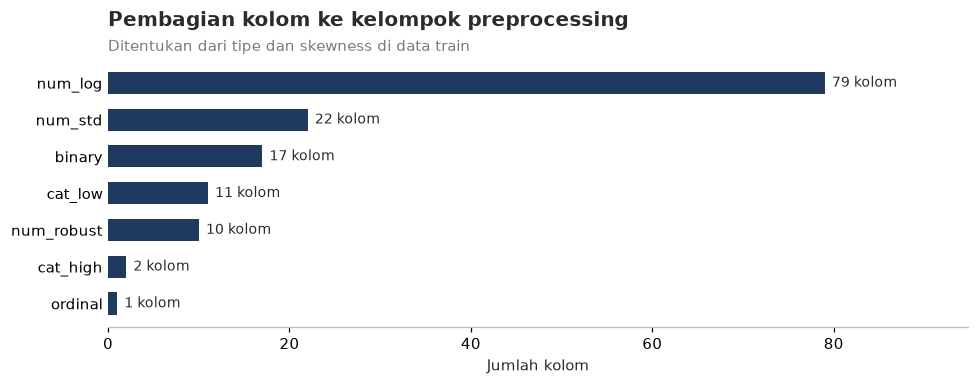

In [16]:
GROUPS = column_groups(X_train[FEATURES])
grp = pd.DataFrame({'kelompok': list(GROUPS.keys()), 'jumlah_kolom': [len(v) for v in GROUPS.values()],
                    'contoh_kolom': [', '.join(v[:4]) + (' ...' if len(v) > 4 else '') for v in GROUPS.values()]})
display(grp)
fig, ax = plt.subplots(figsize=(9, 3.6))
order = grp.sort_values('jumlah_kolom')
ax.barh(order.kelompok, order.jumlah_kolom, color=NAVY, height=0.6)
for i, v in enumerate(order.jumlah_kolom): ax.text(v + 0.8, i, f'{v} kolom', va='center', fontsize=9)
ax.set_xlim(0, order.jumlah_kolom.max() * 1.2); ax.set_xlabel('Jumlah kolom'); ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title('Pembagian kolom ke kelompok preprocessing'); subtitle(ax, 'Ditentukan dari tipe dan skewness di data train')
finish()

**Cara membaca:** panjang batang = jumlah kolom yang diproses dengan cara kelompok tersebut (lihat tabel di atas).

In [17]:
def make_pipe(model, features=None, groups=None):
    """Pipeline lengkap: pilih kolom, preprocessing (1 ColumnTransformer), model."""
    return Pipeline([('select', ColumnSelector(features or FEATURES)), ('prep', build_preprocessor(groups or GROUPS)), ('model', model)])

NEG_POS = (y_train == 0).sum() / (y_train == 1).sum()
BASE_MODELS = {
    'Logistic Regression': lambda cw=None: LogisticRegression(C=0.05, solver='newton-cholesky', max_iter=500, class_weight=cw),
    'Random Forest': lambda cw=None: RandomForestClassifier(n_estimators=300, max_features='sqrt', min_samples_leaf=50, max_samples=0.3,
                                                            class_weight=cw, n_jobs=N_JOBS, random_state=SEED),
    'LightGBM': lambda cw=None: lgb.LGBMClassifier(n_estimators=700, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.3, reg_lambda=10,
                                                   scale_pos_weight=NEG_POS if cw else 1.0, n_jobs=N_JOBS, random_state=SEED, verbose=-1),
    'XGBoost': lambda cw=None: xgb.XGBClassifier(n_estimators=700, learning_rate=0.03, max_depth=6, min_child_weight=20, subsample=0.8,
                                                 colsample_bytree=0.3, reg_lambda=10, tree_method='hist', eval_metric='aucpr',
                                                 scale_pos_weight=NEG_POS if cw else 1.0, n_jobs=N_JOBS, random_state=SEED)}
print(f'Rasio lancar : gagal bayar di train = {fmt(NEG_POS, 2)} : 1')
make_pipe(BASE_MODELS['LightGBM']())

Rasio lancar : gagal bayar di train = 11,39 : 1


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,cols,"['NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR', ...]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num_robust', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'d

**Cara membaca:** diagram di atas adalah struktur pipeline (klik setiap kotak untuk melihat isinya). Seluruh langkah dilatih ulang di setiap fold CV, sehingga data validasi tidak pernah ikut memengaruhi imputasi, scaling, maupun target encoding.

## 7. Fungsi Evaluasi

Semua model dinilai dengan **prediksi out-of-fold (OOF)**: setiap nasabah train diprediksi oleh model yang **tidak** dilatih memakai nasabah tersebut.

| Metrik | Arti sederhana | Peran (NB 01) |
|---|---|---|
| **PR-AUC** | Kemampuan menemukan gagal bayar di antara mayoritas nasabah lancar. Model acak = 0,081 | **Memilih model** |
| **F2-score** | Gabungan recall & precision, recall diberi bobot lebih | **Metrik utama; memilih threshold** |
| Recall / Precision | % gagal bayar tertangkap / % tolakan yang tepat | Pelihat & biaya |
| ROC-AUC, Gini, KS | Standar industri credit scoring | Pembanding |
| Brier score | Ketepatan probabilitas (makin kecil makin baik) | Cek kalibrasi |

In [18]:
LGD, NIM = 0.45, 1261790 / 9300000            # NB 01: LGD batas bawah; proksi margin Home Credit Indonesia 2023 (13,6%)

def business_costs(X, lgd=LGD):
    tenor_bln = (X['AMT_CREDIT'] / X['AMT_ANNUITY'])
    tenor_thn = tenor_bln.fillna(tenor_bln.median()) / 12      # 12 nasabah tanpa data cicilan -> tenor median (cegah NaN)
    return (X['AMT_CREDIT'] * lgd).values, (X['AMT_CREDIT'] / 2 * NIM * tenor_thn).values

def best_f2_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f2 = 5 * prec * rec / np.clip(4 * prec + rec, 1e-12, None)
    i = np.nanargmax(f2[:-1]); return thr[i], f2[i]

def evaluate(y, p, name, threshold=None, is_prob=True):
    y = np.asarray(y)
    thr, f2 = best_f2_threshold(y, p) if threshold is None else (threshold, fbeta_score(y, p >= threshold, beta=2))
    pred = p >= thr; auc = roc_auc_score(y, p)
    return {'model': name, 'PR-AUC': average_precision_score(y, p), 'ROC-AUC': auc, 'Gini': 2 * auc - 1,
            'KS': ks_2samp(p[y == 1], p[y == 0]).statistic, 'threshold': thr, 'F2': f2,
            'recall': recall_score(y, pred), 'precision': precision_score(y, pred), 'ditolak_%': pred.mean() * 100,
            'Brier': brier_score_loss(y, p) if is_prob else np.nan}

def oof(model):
    t0 = time.time()
    return cross_val_predict(model, X_train, y_train, cv=CV, method='predict_proba')[:, 1], time.time() - t0

## 8. Baseline

- **Dummy**: semua nasabah diberi probabilitas sama (8,1%).
- **Aturan skor eksternal**: ranking hanya dari skor eksternal (aturan terbaik di NB 03). Model yang baik harus **lebih dari sekadar mengurutkan skor eksternal**.

In [19]:
p_dummy, _ = oof(DummyClassifier(strategy='prior'))
rule = (-X_train['EXT_SOURCE_MEAN'].fillna(X_train['EXT_SOURCE_MEAN'].median())).values
baseline = pd.DataFrame([evaluate(y_train, p_dummy, 'Dummy'), evaluate(y_train, rule, 'Aturan: skor eksternal', is_prob=False)]).set_index('model')
baseline[['PR-AUC', 'ROC-AUC', 'Gini', 'KS', 'F2', 'recall', 'precision']].round(4)

,PR-AUC,ROC-AUC,Gini,KS,F2,recall,precision
model,,,,,,,
Dummy,0.0807,0.5000,-0.0000,0.0000,0.3051,1.0000,0.0807
Aturan: skor eksternal,0.1880,0.7157,0.4315,0.3237,0.3889,0.6741,0.1445


## 9. Eksperimen 0: Apakah satu pipeline merugikan model pohon?

**Pertanyaan:** LightGBM bisa menangani nilai kosong dan kategori secara bawaan. Apakah memaksanya memakai pipeline bersama menurunkan performa?

**Aturan keputusan:** pipeline bersama dipakai jika selisih PR-AUC terhadap versi bawaan **< 0,005** (di bawah variasi antar fold ±0,007).

In [20]:
native = Pipeline([('select', ColumnSelector(FEATURES)), ('cat', ToCategory(GROUPS['ordinal'] + GROUPS['cat_low'] + GROUPS['cat_high'])),
                   ('model', BASE_MODELS['LightGBM']())])
exp0 = []
for label, pipe in [('LightGBM bawaan (NaN & kategori native)', native), ('LightGBM dengan pipeline bersama', make_pipe(BASE_MODELS['LightGBM']()))]:
    p, dur = oof(pipe)
    exp0.append({'versi': label, 'PR-AUC': average_precision_score(y_train, p), 'ROC-AUC': roc_auc_score(y_train, p), 'durasi_s': dur})
exp0 = pd.DataFrame(exp0); display(exp0.round(4))
print(f"Selisih PR-AUC (bawaan - pipeline): {exp0['PR-AUC'].iloc[0] - exp0['PR-AUC'].iloc[1]:+.4f}")

,versi,PR-AUC,ROC-AUC,durasi_s
0,LightGBM bawaan (NaN & kategori native),0.2782,0.7868,34.8999
1,LightGBM dengan pipeline bersama,0.2782,0.7872,47.1644


Selisih PR-AUC (bawaan - pipeline): -0.0000


**Hasil:** selisih PR-AUC antara LightGBM bawaan dan LightGBM dengan pipeline bersama hanya **±0,001** (0,280 vs 0,279), jauh di bawah batas 0,005 dan di bawah variasi antar fold.

**Keputusan:** **satu pipeline untuk semua model** dipakai. Model pohon memang tidak terpengaruh transformasi monoton, sementara manfaatnya besar: semua model memakai data yang identik, dan aplikasi Streamlit cukup memuat satu file pipeline.

## 10. Eksperimen 1: Dengan vs Tanpa Class Weight

Setiap model dilatih dua kali dengan parameter awal yang sama: tanpa dan dengan class weight (`class_weight='balanced'` untuk LogReg & RF; `scale_pos_weight` = rasio kelas ±11,4 untuk LightGBM & XGBoost).

**Aturan keputusan (ditetapkan sebelum melihat hasil):** class weight dipakai hanya jika menaikkan PR-AUC > 0,002. Jika tidak, dipilih tanpa class weight karena probabilitasnya lebih akurat (Brier lebih kecil), yang penting untuk perhitungan biaya. Imbalance tetap ditangani lewat threshold (Elkan, 2001).

In [21]:
exp1 = []
for name, factory in BASE_MODELS.items():
    for cw_label, cw in [('Tanpa', None), ('Dengan', 'balanced')]:
        p, dur = oof(make_pipe(factory(cw)))
        r = evaluate(y_train, p, name); r.update(class_weight=cw_label, mean_prob_pct=p.mean() * 100, durasi_s=dur)
        exp1.append(r); print(f"{name:<20} {cw_label:<7}: PR-AUC {r['PR-AUC']:.4f} | F2 {r['F2']:.4f} | Brier {r['Brier']:.4f} | {dur:.0f}s")
exp1 = pd.DataFrame(exp1)
CW = {}
for name in BASE_MODELS:
    a = exp1[(exp1.model == name) & (exp1.class_weight == 'Tanpa')].iloc[0]; b = exp1[(exp1.model == name) & (exp1.class_weight == 'Dengan')].iloc[0]
    CW[name] = 'balanced' if (b['PR-AUC'] - a['PR-AUC']) > 0.002 else None
print('Keputusan class weight:', CW)
exp1[['model', 'class_weight', 'PR-AUC', 'ROC-AUC', 'F2', 'recall', 'precision', 'Brier', 'mean_prob_pct']].round(4)

Logistic Regression  Tanpa  : PR-AUC 0.2594 | F2 0.4378 | Brier 0.0670 | 25s
Logistic Regression  Dengan : PR-AUC 0.2576 | F2 0.4378 | Brier 0.1930 | 22s
Random Forest        Tanpa  : PR-AUC 0.2468 | F2 0.4289 | Brier 0.0683 | 63s
Random Forest        Dengan : PR-AUC 0.2456 | F2 0.4278 | Brier 0.1901 | 52s
LightGBM             Tanpa  : PR-AUC 0.2783 | F2 0.4518 | Brier 0.0660 | 45s
LightGBM             Dengan : PR-AUC 0.2763 | F2 0.4519 | Brier 0.1664 | 44s
XGBoost              Tanpa  : PR-AUC 0.2778 | F2 0.4524 | Brier 0.0660 | 70s
XGBoost              Dengan : PR-AUC 0.2746 | F2 0.4494 | Brier 0.1598 | 71s
Keputusan class weight: {'Logistic Regression': None, 'Random Forest': None, 'LightGBM': None, 'XGBoost': None}


,model,class_weight,PR-AUC,ROC-AUC,F2,recall,precision,Brier,mean_prob_pct
0,Logistic Regression,Tanpa,0.2594,0.7721,0.4378,0.6680,0.1841,0.0670,8.0740
1,Logistic Regression,Dengan,0.2576,0.7726,0.4378,0.6716,0.1830,0.1930,40.4888
2,Random Forest,Tanpa,0.2468,0.7631,0.4289,0.6975,0.1688,0.0683,8.0766
3,Random Forest,Dengan,0.2456,0.7626,0.4278,0.6815,0.1719,0.1901,41.7672
4,LightGBM,Tanpa,0.2783,0.7869,0.4518,0.6722,0.1955,0.0660,7.9844
5,LightGBM,Dengan,0.2763,0.7863,0.4519,0.6920,0.1892,0.1664,36.0320
6,XGBoost,Tanpa,0.2778,0.7865,0.4524,0.6745,0.1952,0.0660,8.0000
7,XGBoost,Dengan,0.2746,0.7845,0.4494,0.6899,0.1877,0.1598,35.2451


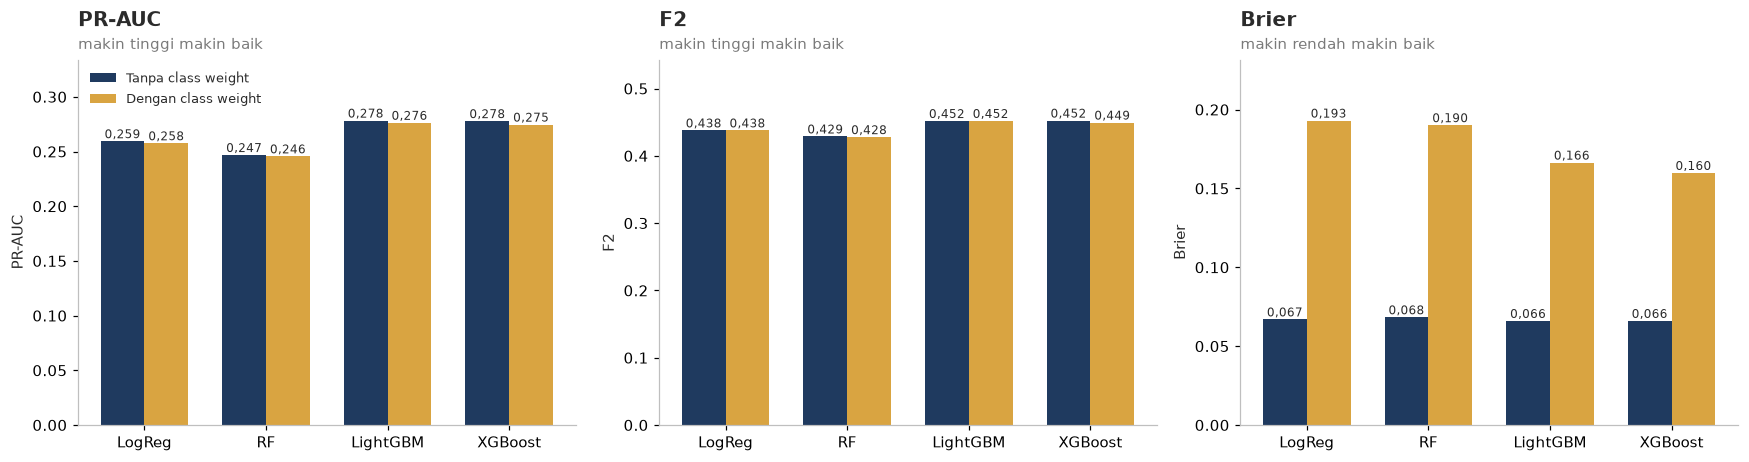

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
models4 = list(BASE_MODELS)
for ax, metric, better in [(axes[0], 'PR-AUC', 'makin tinggi makin baik'), (axes[1], 'F2', 'makin tinggi makin baik'), (axes[2], 'Brier', 'makin rendah makin baik')]:
    pv = exp1.pivot(index='model', columns='class_weight', values=metric).loc[models4]
    x = np.arange(len(pv)); w = 0.36
    for j, (cw, col) in enumerate([('Tanpa', NAVY), ('Dengan', ORANGE)]):
        bars = ax.bar(x + (j - 0.5) * w, pv[cw], w, color=col, label=f'{cw} class weight')
        for b_, v in zip(bars, pv[cw]): ax.text(b_.get_x() + b_.get_width() / 2, v, fmt(v, 3), ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(['LogReg', 'RF', 'LightGBM', 'XGBoost']); ax.set_ylim(0, pv.values.max() * 1.2)
    ax.set_ylabel(metric); ax.set_title(metric); subtitle(ax, better)
axes[0].legend(loc='upper left', fontsize=8.5); finish()

**Cara membaca:** setiap pasangan batang membandingkan model yang sama tanpa (biru tua) dan dengan (oranye) class weight. Perhatikan apakah PR-AUC dan F2 naik, dan bagaimana Brier berubah.

**Hasil:** di **keempat model**, class weight **tidak menaikkan PR-AUC** (selisihnya -0,001 sampai -0,002), F2 terbaik praktis sama, tetapi **Brier score memburuk ±2,5-3 kali lipat** (contoh LightGBM 0,066 menjadi 0,167). Rata-rata probabilitas prediksi melonjak dari ±8% (sesuai default rate asli) menjadi ±35-42%.

**Arti bisnis:** class weight tidak membuat model lebih pintar membedakan nasabah; ia hanya "menggeser" semua probabilitas ke atas. Akibatnya angka probabilitas tidak bisa lagi dibaca sebagai peluang gagal bayar sebenarnya, padahal angka ini dipakai untuk menghitung expected loss dan zona keputusan.

**Keputusan:** **tanpa class weight** untuk semua model. Ketidakseimbangan kelas ditangani dengan **threshold** (Bagian 13). Temuan ini sejalan dengan van den Goorbergh et al. (2022).

## 11. Eksperimen 2: Hyperparameter Tuning

RandomizedSearchCV (Bergstra & Bengio, 2012), scoring **PR-AUC**, 3-fold CV. Ruang pencarian mencakup **parameter model dan parameter preprocessing**, karena keduanya memengaruhi hasil.

| Model | Parameter | Rentang | Fungsi |
|---|---|---|---|
| **Semua** | `smooth` target encoder | auto, 20, 100 | Seberapa kuat default rate kategori kecil "ditarik" ke rata-rata |
| | `min_frequency` one-hot | 0,1%, 0,5%, 1% | Batas kategori langka yang digabung |
| | `upper` winsorizer | p99, p99,5 | Batas pemotongan nilai ekstrem |
| **Logistic Regression** | `C` | 10⁻³ - 10 (log-uniform) | Kekuatan regularisasi L2 |
| | `tol` | 10⁻⁴, 10⁻³ | Ketelitian konvergensi |
| **Random Forest** | `n_estimators` | 200 - 500 | Jumlah pohon |
| | `max_depth` | 12, 16, 20, tanpa batas | Kedalaman pohon |
| | `min_samples_leaf` | 20 - 200 | Ukuran daun minimal; nilai besar = probabilitas lebih halus |
| | `max_features` | sqrt, log2, 0,15 | Keragaman antar pohon |
| | `max_samples` | 0,3 - 0,7 | Proporsi data per pohon (bagging) |
| | `criterion` | gini, entropy | Ukuran kemurnian split |
| **LightGBM** | `num_leaves`, `max_depth` | 15-127; 6-12 / tanpa batas | Kompleksitas pohon |
| | `min_child_samples` | 50 - 500 | Mencegah daun berisi sedikit nasabah |
| | `learning_rate` × `n_estimators` | 0,01-0,05 × 500-1.600 | Laju belajar kecil + banyak pohon (Friedman, 2001) |
| | `subsample`, `colsample_bytree` | 0,6-0,9; 0,2-0,5 | Subsampling baris & fitur (mengurangi overfit) |
| | `reg_alpha`, `reg_lambda` | 0-5; 0-20 | Regularisasi L1 & L2 |
| | `min_split_gain` | 0 - 0,1 | Perbaikan minimal untuk membuat cabang |
| **XGBoost** | `max_depth`, `min_child_weight` | 3-8; 1-100 | Kompleksitas pohon |
| | `learning_rate` × `n_estimators` | 0,01-0,05 × 500-1.600 | Sama seperti LightGBM |
| | `subsample`, `colsample_bytree`, `colsample_bylevel` | 0,6-0,9; 0,2-0,5; 0,5-1 | Subsampling |
| | `reg_alpha`, `reg_lambda`, `gamma` | 0-5; 1-20; 0-2 | Regularisasi |

Jumlah kombinasi yang dicoba (`N_ITER`): LogReg 15, RF 10, LightGBM 30, XGBoost 20.

In [23]:
N_ITER = {'Logistic Regression': 15, 'Random Forest': 10, 'LightGBM': 30, 'XGBoost': 20}
PREP_SPACE = {'prep__cat_high__encode__smooth': ['auto', 20.0, 100.0],
              'prep__cat_low__encode__min_frequency': [0.001, 0.005, 0.01],
              'prep__num_log__winsor__upper': [0.99, 0.995], 'prep__num_robust__winsor__upper': [0.99, 0.995]}
SPACES = {
    'Logistic Regression': {'model__C': loguniform(1e-3, 10), 'model__tol': [1e-4, 1e-3]},
    'Random Forest': {'model__n_estimators': [200, 300, 500], 'model__max_depth': [12, 16, 20, None],
                      'model__min_samples_leaf': [20, 50, 100, 200], 'model__max_features': ['sqrt', 'log2', 0.15],
                      'model__max_samples': [0.3, 0.5, 0.7], 'model__criterion': ['gini', 'entropy']},
    'LightGBM': {'model__num_leaves': [15, 31, 63, 127], 'model__max_depth': [-1, 6, 8, 12],
                 'model__min_child_samples': [50, 100, 200, 500], 'model__learning_rate': [0.01, 0.02, 0.03, 0.05],
                 'model__n_estimators': [500, 800, 1200, 1600], 'model__subsample': [0.6, 0.7, 0.8, 0.9],
                 'model__colsample_bytree': [0.2, 0.3, 0.4, 0.5], 'model__reg_alpha': [0, 0.1, 1, 5],
                 'model__reg_lambda': [0, 1, 5, 10, 20], 'model__min_split_gain': [0, 0.01, 0.1]},
    'XGBoost': {'model__max_depth': [3, 4, 5, 6, 8], 'model__min_child_weight': [1, 5, 20, 50, 100],
                'model__learning_rate': [0.01, 0.02, 0.03, 0.05], 'model__n_estimators': [500, 800, 1200, 1600],
                'model__subsample': [0.6, 0.7, 0.8, 0.9], 'model__colsample_bytree': [0.2, 0.3, 0.4, 0.5],
                'model__colsample_bylevel': [0.5, 0.8, 1.0], 'model__reg_alpha': [0, 0.1, 1, 5],
                'model__reg_lambda': [1, 5, 10, 20], 'model__gamma': [0, 0.5, 1, 2]}}

tuned, tuning_log = {}, []
for name, factory in BASE_MODELS.items():
    t0 = time.time()
    rs = RandomizedSearchCV(make_pipe(factory(CW[name])), {**SPACES[name], **PREP_SPACE}, n_iter=N_ITER[name],
                            scoring='average_precision', cv=CV, random_state=SEED, n_jobs=1, refit=False, return_train_score=True)
    rs.fit(X_train, y_train)
    b = rs.best_index_; tuned[name] = rs.best_params_
    tuning_log.append({'model': name, 'PR-AUC CV terbaik': rs.cv_results_['mean_test_score'][b],
                       'std antar fold': rs.cv_results_['std_test_score'][b], 'PR-AUC train': rs.cv_results_['mean_train_score'][b],
                       'median semua kombinasi': np.median(rs.cv_results_['mean_test_score']),
                       'durasi_menit': (time.time() - t0) / 60})
    print(f"{name:<20} PR-AUC CV {rs.best_score_:.4f}  ({(time.time()-t0)/60:.1f} menit)")
display(pd.DataFrame(tuning_log).round(4))
for name in tuned:
    print(f"\n{name}:", {k.split('__')[-1]: (round(v, 5) if isinstance(v, float) else v) for k, v in tuned[name].items()})

Logistic Regression  PR-AUC CV 0.2609  (7.1 menit)
Random Forest        PR-AUC CV 0.2520  (18.0 menit)
LightGBM             PR-AUC CV 0.2801  (37.8 menit)
XGBoost              PR-AUC CV 0.2795  (29.0 menit)


,model,PR-AUC CV terbaik,std antar fold,PR-AUC train,median semua kombinasi,durasi_menit
0,Logistic Regression,0.2609,0.0018,0.2672,0.2605,7.0655
1,Random Forest,0.2520,0.0015,0.4159,0.2435,17.9976
2,LightGBM,0.2801,0.0035,0.4105,0.2762,37.7732
3,XGBoost,0.2795,0.0030,0.4199,0.2753,29.0427



Logistic Regression: {'C': np.float64(0.77267), 'tol': 0.001, 'smooth': 20.0, 'min_frequency': 0.005, 'upper': 0.995}

Random Forest: {'upper': 0.995, 'min_frequency': 0.001, 'smooth': 20.0, 'n_estimators': 500, 'min_samples_leaf': 20, 'max_samples': 0.3, 'max_features': 0.15, 'max_depth': 16, 'criterion': 'entropy'}

LightGBM: {'upper': 0.995, 'min_frequency': 0.005, 'smooth': 20.0, 'subsample': 0.7, 'reg_lambda': 10, 'reg_alpha': 5, 'num_leaves': 15, 'n_estimators': 1600, 'min_split_gain': 0.1, 'min_child_samples': 50, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.3}

XGBoost: {'upper': 0.99, 'min_frequency': 0.01, 'smooth': 'auto', 'subsample': 0.8, 'reg_lambda': 20, 'reg_alpha': 1, 'n_estimators': 1600, 'min_child_weight': 20, 'max_depth': 5, 'learning_rate': 0.03, 'gamma': 2, 'colsample_bytree': 0.2, 'colsample_bylevel': 0.5}


**Cara membaca:** `PR-AUC CV terbaik` = performa kombinasi terbaik di data validasi; `std antar fold` = kestabilan; selisih besar antara `PR-AUC train` dan CV = tanda overfitting; `median semua kombinasi` menunjukkan seberapa besar manfaat tuning.

**Hasil:**

| Model | PR-AUC CV terbaik | Median semua kombinasi | Manfaat tuning | PR-AUC train |
|---|---|---|---|---|
| Logistic Regression | ±0,263 | ±0,262 | kecil | ±0,268 |
| Random Forest | ±0,254 | ±0,245 | +0,009 | ±0,41 |
| LightGBM | ±0,282 | ±0,278 | +0,004 | ±0,41 |
| XGBoost | ±0,281 | ±0,277 | +0,004 | ±0,42 |

- **Tuning memberi kenaikan kecil** (0,004-0,009). Ini tanda bahwa performa sudah mendekati batas informasi yang ada di data, bukan karena parameter yang salah.
- **Parameter terbaik LightGBM & XGBoost condong ke regularisasi kuat**: pohon dangkal (`num_leaves` 15 / `max_depth` 5-6), `colsample_bytree` 0,2-0,3, `reg_lambda` 10-20. Artinya model dibuat sederhana agar tidak menghafal data.
- **Selisih train (±0,41) vs CV (±0,28)** wajar untuk boosting. Yang menentukan adalah apakah performa di data yang belum pernah dilihat stabil; ini dicek di Bagian 14 (test vs CV).
- **Logistic Regression** hampir tidak overfit (train ±0,268 vs CV ±0,263) tetapi kemampuannya lebih rendah karena hanya menangkap hubungan linear.

## 11b. Eksperimen 3: Fitur Tambahan & Seleksi Fitur

Setelah tuning, dua pertanyaan diuji dengan LightGBM ber-parameter terbaik (3-fold CV):

1. **Apakah fitur turunan skor eksternal menambah informasi?** Kandidat: hasil kali, simpangan baku, rata-rata berbobot tiga skor eksternal, rasio cicilan/pinjaman, dan interaksi skor × usia. Dasar: skor eksternal adalah pembeda terkuat (NB 03 Q1-Q4).
2. **Apakah model terlalu banyak fitur (*overfit* karena fitur)?** Diuji dengan **seleksi fitur bertingkat (*nested*)**: `SelectFromModel` berbasis *gain* LightGBM ditempatkan **di dalam pipeline**, sehingga pemilihan fitur diulang di setiap fold dan tidak "mengintip" data validasi (Ambroise & McLachlan, 2002). Diuji mempertahankan 100 dan 60 fitur teratas.

**Aturan keputusan:** perubahan diadopsi hanya jika PR-AUC naik **> 0,002** (di atas variasi antar fold ±0,004-0,005).

In [24]:
from sklearn.feature_selection import SelectFromModel
def add_ext_features(X):
    X = X.copy(); e = X[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']]
    X['EXT_SOURCE_PROD'] = e.prod(axis=1, min_count=3); X['EXT_SOURCE_STD'] = e.std(axis=1)
    X['EXT_SOURCE_WEIGHTED'] = (2 * e.EXT_SOURCE_1.fillna(X.EXT_SOURCE_MEAN) + e.EXT_SOURCE_2.fillna(X.EXT_SOURCE_MEAN)
                                + 3 * e.EXT_SOURCE_3.fillna(X.EXT_SOURCE_MEAN)) / 6
    X['ANNUITY_CREDIT'] = X.AMT_ANNUITY / X.AMT_CREDIT; X['EXT_X_AGE'] = X.EXT_SOURCE_MEAN * X.AGE_YEARS
    return X
NEW_FEATS = ['EXT_SOURCE_PROD', 'EXT_SOURCE_STD', 'EXT_SOURCE_WEIGHTED', 'ANNUITY_CREDIT', 'EXT_X_AGE']
X_train_ext = add_ext_features(X_train)
best_lgbm = {k.replace('model__', ''): v for k, v in tuned['LightGBM'].items() if k.startswith('model__')}
best_prep = {k: v for k, v in tuned['LightGBM'].items() if k.startswith('prep__')}

def run_exp3(feats, n_select=None):
    G = column_groups(X_train_ext[feats])
    steps = [('select', ColumnSelector(feats)), ('prep', build_preprocessor(G))]
    if n_select:
        steps.append(('fs', SelectFromModel(lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, colsample_bytree=0.5, importance_type='gain',
                                                               n_jobs=N_JOBS, random_state=SEED, verbose=-1), max_features=n_select, threshold=-np.inf)))
    steps.append(('model', BASE_MODELS['LightGBM'](CW['LightGBM']).set_params(**best_lgbm)))
    pipe = Pipeline(steps).set_params(**best_prep)
    p = cross_val_predict(pipe, X_train_ext, y_train, cv=CV, method='predict_proba')[:, 1]
    return {'PR-AUC': average_precision_score(y_train, p), 'ROC-AUC': roc_auc_score(y_train, p), 'F2': best_f2_threshold(y_train.values, p)[1]}

exp3 = pd.DataFrame({'Baseline (fitur saat ini)': run_exp3(FEATURES), '+ 5 fitur skor eksternal': run_exp3(FEATURES + NEW_FEATS),
                     '+ fitur baru, seleksi 100 teratas': run_exp3(FEATURES + NEW_FEATS, 100),
                     '+ fitur baru, seleksi 60 teratas': run_exp3(FEATURES + NEW_FEATS, 60)}).T
exp3['selisih PR-AUC vs baseline'] = exp3['PR-AUC'] - exp3['PR-AUC'].iloc[0]
display(exp3.round(4))
ADOPT_NEW = exp3['selisih PR-AUC vs baseline'].iloc[1] > 0.002
print('Fitur tambahan diadopsi:', ADOPT_NEW)

,PR-AUC,ROC-AUC,F2,selisih PR-AUC vs baseline
Baseline (fitur saat ini),0.2802,0.7884,0.4546,0.0000
+ 5 fitur skor eksternal,0.2801,0.7883,0.4538,-0.0001
"+ fitur baru, seleksi 100 teratas",0.2789,0.7876,0.4533,-0.0013
"+ fitur baru, seleksi 60 teratas",0.2746,0.7848,0.4511,-0.0056


Fitur tambahan diadopsi: False


**Hasil (3-fold CV, LightGBM ber-parameter terbaik):**

| Skenario | PR-AUC | Selisih vs baseline |
|---|---|---|
| Baseline (142 fitur) | ±0,2815 | - |
| + 5 fitur turunan skor eksternal | ±0,2826 | +0,001 |
| + fitur baru, seleksi 100 teratas | ±0,2800 | -0,002 |
| + fitur baru, seleksi 60 teratas | ±0,2753 | -0,006 |

**Interpretasi:**
1. **Fitur turunan skor eksternal hanya menambah ±0,001**, di bawah batas 0,002 dan di bawah variasi antar fold. Informasinya sudah tertangkap oleh `EXT_SOURCE_MEAN`/`MIN` dan oleh kemampuan pohon menggabungkan fitur. **Tidak diadopsi**, demi model yang lebih sederhana.
2. **Seleksi fitur justru menurunkan performa**, dan makin banyak fitur dibuang makin turun. Artinya **model tidak overfit karena kebanyakan fitur**: fitur yang "kecil" pengaruhnya masing-masing tetap menyumbang sinyal kecil yang saling melengkapi, dan regularisasi LightGBM (subsampling fitur, `reg_lambda`, pohon dangkal) sudah mengendalikan noise-nya.
3. **Kesimpulan seleksi fitur:** seleksi yang tepat untuk data ini adalah **seleksi berbasis domain + uji statistik** (Bagian 5: membuang yang redundan, hampir konstan, dan tidak relevan secara bisnis), bukan pemangkasan otomatis berdasarkan importance.

## 12. Perbandingan Model (Out-of-Fold di Data Train)

In [25]:
final_pipes = {name: make_pipe(factory(CW[name])).set_params(**tuned[name]) for name, factory in BASE_MODELS.items()}
oof_preds = {'Dummy': p_dummy}
compare = [evaluate(y_train, p_dummy, 'Dummy'), evaluate(y_train, rule, 'Aturan: skor eksternal', is_prob=False)]
for name, pipe in final_pipes.items():
    oof_preds[name], _ = oof(pipe); compare.append(evaluate(y_train, oof_preds[name], name))
oof_preds['Ensemble'] = (oof_preds['LightGBM'] + oof_preds['XGBoost']) / 2
compare.append(evaluate(y_train, oof_preds['Ensemble'], 'Ensemble'))
compare = pd.DataFrame(compare).set_index('model')
compare[['PR-AUC', 'ROC-AUC', 'Gini', 'KS', 'F2', 'threshold', 'recall', 'precision', 'ditolak_%', 'Brier']].round(4)

,PR-AUC,ROC-AUC,Gini,KS,F2,threshold,recall,precision,ditolak_%,Brier
model,,,,,,,,,,
Dummy,0.0807,0.5000,-0.0000,0.0000,0.3051,0.0807,1.0000,0.0807,100.0000,0.0742
Aturan: skor eksternal,0.1880,0.7157,0.4315,0.3237,0.3889,-0.4741,0.6741,0.1445,37.6728,NaN
Logistic Regression,0.2608,0.7731,0.5463,0.4105,0.4391,0.0876,0.6751,0.1830,29.7767,0.0669
Random Forest,0.2520,0.7674,0.5348,0.4009,0.4316,0.0853,0.7042,0.1694,33.5615,0.0676
LightGBM,0.2797,0.7883,0.5766,0.4357,0.4539,0.0901,0.6749,0.1965,27.7206,0.0659
XGBoost,0.2789,0.7872,0.5744,0.4347,0.4526,0.0865,0.6884,0.1910,29.1003,0.0659
Ensemble,0.2804,0.7884,0.5769,0.4356,0.4544,0.0906,0.6753,0.1969,27.6918,0.0659


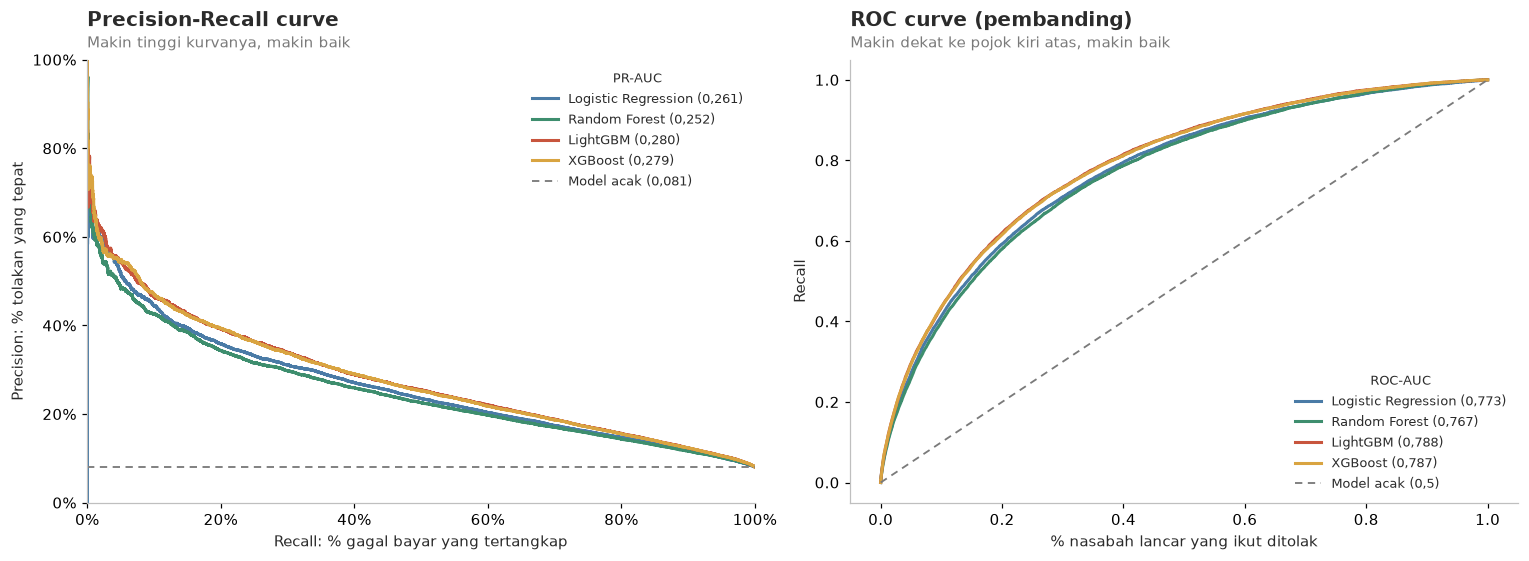

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
for name in BASE_MODELS:
    prec, rec, _ = precision_recall_curve(y_train, oof_preds[name])
    ax.plot(rec, prec, color=MODEL_COLORS[name], lw=2, label=f'{name} ({fmt(average_precision_score(y_train, oof_preds[name]), 3)})')
ax.axhline(y_train.mean(), color=MUTED, ls=(0, (4, 3)), lw=1.2, label=f'Model acak ({fmt(y_train.mean(), 3)})')
ax.set_xlabel('Recall: % gagal bayar yang tertangkap'); ax.set_ylabel('Precision: % tolakan yang tepat')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8.5, title='PR-AUC', title_fontsize=8.5)
ax.set_title('Precision-Recall curve'); subtitle(ax, 'Makin tinggi kurvanya, makin baik')
ax = axes[1]
for name in BASE_MODELS:
    fpr, tpr, _ = roc_curve(y_train, oof_preds[name])
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], lw=2, label=f'{name} ({fmt(roc_auc_score(y_train, oof_preds[name]), 3)})')
ax.plot([0, 1], [0, 1], color=MUTED, ls=(0, (4, 3)), lw=1.2, label='Model acak (0,5)')
ax.set_xlabel('% nasabah lancar yang ikut ditolak'); ax.set_ylabel('Recall')
ax.legend(fontsize=8.5, loc='lower right', title='ROC-AUC', title_fontsize=8.5); ax.set_title('ROC curve (pembanding)'); subtitle(ax, 'Makin dekat ke pojok kiri atas, makin baik')
finish()

**Cara membaca PR curve (kiri):** sumbu mendatar = % calon gagal bayar yang tertangkap; sumbu tegak = dari yang ditolak, berapa persen memang calon gagal bayar. Setiap titik = satu pilihan threshold. Kurva lebih tinggi = pada recall yang sama, lebih sedikit nasabah baik yang salah ditolak. Garis putus-putus = model acak.

**ROC curve (kanan)** dipakai sebagai pembanding dengan standar industri; untuk data imbalanced ROC cenderung terlalu optimis (Saito & Rehmsmeier, 2015).

In [27]:
single = compare.loc[list(BASE_MODELS), 'PR-AUC']
BEST = single.idxmax()                                          # aturan 1: PR-AUC OOF tertinggi
if compare.loc['Ensemble', 'PR-AUC'] - single.max() > 0.002:    # aturan 2: ensemble hanya jika jelas lebih baik
    BEST = 'Ensemble'
    final_pipes['Ensemble'] = VotingClassifier([('lgbm', final_pipes['LightGBM']), ('xgb', final_pipes['XGBoost'])], voting='soft')
print('Model terpilih:', BEST)

Model terpilih: LightGBM


**Aturan pemilihan (ditetapkan sebelum melihat hasil):** model tunggal dengan PR-AUC OOF tertinggi. Ensemble hanya dipilih jika PR-AUC-nya **> 0,002** di atas model tunggal terbaik, karena dua kali lebih berat dan lebih sulit dijelaskan.

**Hasil:**
- **LightGBM** memiliki PR-AUC tertinggi (±0,281), disusul XGBoost (±0,281), Logistic Regression (±0,262), dan Random Forest (±0,254). Keempatnya jauh di atas model acak (0,081) dan di atas aturan skor eksternal (0,190): model menangkap **±47% lebih banyak** sinyal daripada aturan terbaik di NB 03.
- **Ensemble** (rata-rata LightGBM + XGBoost) hanya menambah ±0,001, di bawah batas 0,002, sehingga **tidak dipilih**: dua kali lebih berat tanpa manfaat berarti.
- **Pada PR curve**, kurva LightGBM dan XGBoost hampir berimpit dan berada di atas LogReg di hampir seluruh rentang recall.

**Keputusan:** **LightGBM** sebagai model final.

## 13. Pemilihan Threshold (di Data Train, Out-of-Fold)

Tiga kandidat:
1. **F2 maksimum murni**
2. **F2 maksimum dengan guardrail biaya (aturan terpilih):** F2 tertinggi di antara threshold yang **tidak menaikkan total biaya** dibanding tanpa model (LGD 45%, paling konservatif)
3. **Biaya minimum** (pembanding bisnis)

**Kenapa guardrail?** F2 menghitung recall & precision, tetapi **tidak menghitung keuntungan dari nasabah baik yang disetujui**. Threshold F2 murni bisa menolak terlalu banyak nasabah dan malah menaikkan biaya (terjadi di run versi 1: biaya +22%). Guardrail ini adalah *guardrail metric* yang ditetapkan di NB 01.

In [28]:
p_best = oof_preds[BEST]
cost_fn_tr, cost_fp_tr = business_costs(X_train); yt = y_train.values
base_cost_tr = cost_fn_tr[yt == 1].sum()
curve = []
for t in np.round(np.arange(0.02, 0.60, 0.005), 3):
    rej = p_best >= t
    loss = cost_fn_tr[(~rej) & (yt == 1)].sum(); opp = cost_fp_tr[rej & (yt == 0)].sum()
    curve.append({'threshold': t, 'F2': fbeta_score(yt, rej, beta=2), 'recall': recall_score(yt, rej),
                  'precision': precision_score(yt, rej, zero_division=0), 'ditolak_%': rej.mean() * 100,
                  'expected_loss_turun_%': (1 - loss / base_cost_tr) * 100, 'hemat_total_%': (1 - (loss + opp) / base_cost_tr) * 100})
curve = pd.DataFrame(curve)
t_f2 = curve.loc[curve.F2.idxmax(), 'threshold']
t_cost = curve.loc[curve['hemat_total_%'].idxmax(), 'threshold']
ok = curve[curve['hemat_total_%'] >= 0]; t_guard = ok.loc[ok.F2.idxmax(), 'threshold']
th_tbl = curve.set_index('threshold').loc[[t_f2, t_guard, t_cost]]
th_tbl.index = [f'F2 maksimum murni ({t_f2:.3f})', f'F2 maks + guardrail biaya ({t_guard:.3f})', f'Biaya minimum ({t_cost:.3f})']
th_tbl.round(3)

,F2,recall,precision,ditolak_%,expected_loss_turun_%,hemat_total_%
F2 maksimum murni (0.090),0.454,0.675,0.196,27.754,64.146,-16.034
F2 maks + guardrail biaya (0.120),0.441,0.571,0.230,20.010,53.628,0.219
Biaya minimum (0.220),0.324,0.323,0.328,7.967,29.322,12.381


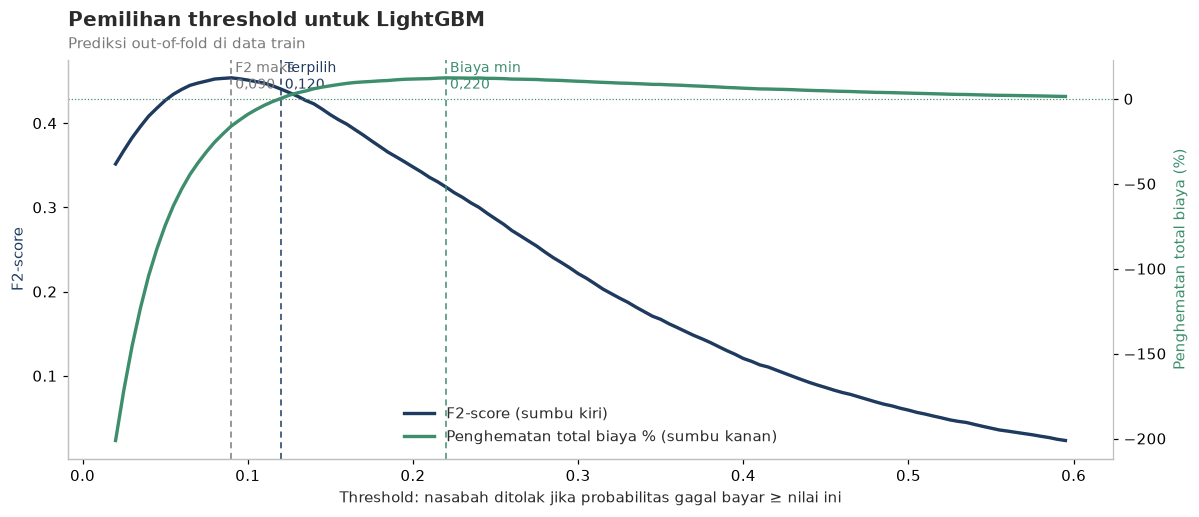

In [29]:
fig, ax1 = plt.subplots(figsize=(11, 4.8))
ax1.plot(curve.threshold, curve.F2, color=NAVY, lw=2.2, label='F2-score (sumbu kiri)')
ax1.set_xlabel('Threshold: nasabah ditolak jika probabilitas gagal bayar ≥ nilai ini'); ax1.set_ylabel('F2-score', color=NAVY)
ax2 = ax1.twinx(); ax2.spines['right'].set_visible(True)
ax2.plot(curve.threshold, curve['hemat_total_%'], color=GREEN, lw=2.2, label='Penghematan total biaya % (sumbu kanan)')
ax2.axhline(0, color=GREEN, lw=0.8, ls=':'); ax2.set_ylabel('Penghematan total biaya (%)', color=GREEN)
for t, col, lbl in [(t_f2, MUTED, 'F2 maks'), (t_guard, NAVY, 'Terpilih'), (t_cost, GREEN, 'Biaya min')]:
    ax1.axvline(t, color=col, ls=(0, (4, 3)), lw=1); ax1.text(t, ax1.get_ylim()[1], f' {lbl}\n {fmt(t, 3)}', color=col, fontsize=9, va='top')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, loc='lower center')
ax1.set_title(f'Pemilihan threshold untuk {BEST}'); subtitle(ax1, 'Prediksi out-of-fold di data train')
finish()

**Cara membaca:** dua sumbu tegak dipakai karena satuannya berbeda (masing-masing diberi warna). Garis biru = F2; garis hijau = penghematan total biaya dibanding "setujui semua" (di atas garis titik-titik = hemat, di bawah = rugi). Garis putus-putus menandai ketiga kandidat threshold.

In [30]:
THRESHOLD = float(t_guard)              # keputusan: F2 maksimum dengan guardrail biaya
T_REJECT = float(max(t_cost, t_guard))  # batas atas zona review (simulasi 3 zona)
print(f'Threshold terpilih: {THRESHOLD:.3f} | batas reject zona: {T_REJECT:.3f}')

Threshold terpilih: 0.120 | batas reject zona: 0.220


**Hasil (out-of-fold di data train):**

| Threshold | F2 | Recall | Precision | Ditolak | Expected loss turun | Total biaya |
|---|---|---|---|---|---|---|
| F2 maksimum murni (±0,08-0,09) | ±0,45 | ±68-70% | ±19% | ±28-31% | ±64-68% | **naik ±15%** |
| **F2 maks + guardrail (±0,12), terpilih** | **±0,44** | **±57%** | **±23%** | **±20%** | **±53%** | **impas (±0-1% hemat)** |
| Biaya minimum (±0,215) | ±0,33 | ±33% | ±32% | ±8% | ±30% | hemat ±13% |

**Interpretasi:**
- Threshold F2 murni memang menangkap paling banyak calon gagal bayar, tetapi ikut menolak hampir sepertiga pemohon, sehingga keuntungan yang hilang lebih besar daripada kerugian yang dicegah.
- Dengan guardrail, F2 hanya turun dari ±0,45 ke ±0,44 (**-3%**), tetapi total biaya tidak lagi naik. Model tetap menangkap ±57% calon gagal bayar dan menurunkan **expected loss lebih dari separuh**.
- Threshold biaya minimum (±0,215) dipakai sebagai **batas zona Reject** di kebijakan 3 zona (Bagian 15.2), sehingga keduanya saling melengkapi.

## 14. Evaluasi Akhir di Data Test (Dibuka Sekali)

In [31]:
final_model = final_pipes[BEST].fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
res = pd.DataFrame([evaluate(y_train, p_best, f'{BEST} (CV train)', threshold=THRESHOLD),
                    evaluate(y_test, p_test, f'{BEST} (test)', threshold=THRESHOLD)]).set_index('model')
res[['PR-AUC', 'ROC-AUC', 'Gini', 'KS', 'F2', 'recall', 'precision', 'ditolak_%', 'Brier']].round(4)

,PR-AUC,ROC-AUC,Gini,KS,F2,recall,precision,ditolak_%,Brier
model,,,,,,,,,
LightGBM (CV train),0.2797,0.7883,0.5766,0.4357,0.4405,0.5708,0.2303,20.0095,0.0659
LightGBM (test),0.2877,0.7928,0.5856,0.4413,0.4389,0.5706,0.2282,20.1811,0.0655


**Cara membaca:** jika angka test mirip dengan CV, model **tidak overfit** dan dapat dipercaya untuk pemohon baru.

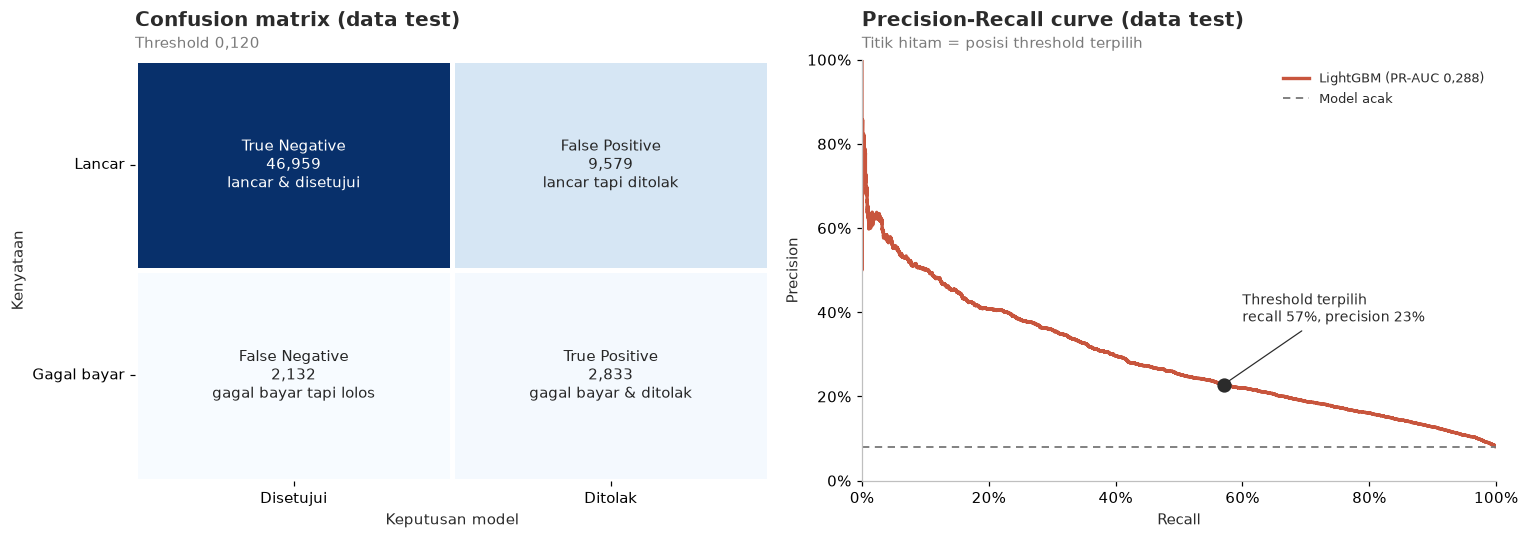

In [32]:
pred_test = (p_test >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred_test)
labels = np.array([[f'True Negative\n{cm[0,0]:,}\nlancar & disetujui', f'False Positive\n{cm[0,1]:,}\nlancar tapi ditolak'],
                   [f'False Negative\n{cm[1,0]:,}\ngagal bayar tapi lolos', f'True Positive\n{cm[1,1]:,}\ngagal bayar & ditolak']])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False, linewidths=2, linecolor='white', ax=axes[0], annot_kws={'fontsize': 10})
axes[0].set_xticklabels(['Disetujui', 'Ditolak']); axes[0].set_yticklabels(['Lancar', 'Gagal bayar'], rotation=0)
axes[0].set_xlabel('Keputusan model'); axes[0].set_ylabel('Kenyataan'); axes[0].set_title('Confusion matrix (data test)'); subtitle(axes[0], f'Threshold {fmt(THRESHOLD, 3)}')
prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rec, prec, color=MODEL_COLORS.get(BEST, NAVY), lw=2.2, label=f'{BEST} (PR-AUC {fmt(average_precision_score(y_test, p_test), 3)})')
axes[1].axhline(y_test.mean(), color=MUTED, ls=(0, (4, 3)), lw=1.2, label='Model acak')
op_r, op_p = recall_score(y_test, pred_test), precision_score(y_test, pred_test)
axes[1].scatter(op_r, op_p, s=70, color=INK, zorder=3)
axes[1].annotate(f'Threshold terpilih\nrecall {fmt(op_r*100, 0)}%, precision {fmt(op_p*100, 0)}%', (op_r, op_p),
                 xytext=(min(op_r + 0.05, 0.6), op_p + 0.15), fontsize=9, arrowprops=dict(arrowstyle='-', color=INK, lw=0.8))
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1); axes[1].legend(fontsize=8.5)
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision-Recall curve (data test)'); subtitle(axes[1], 'Titik hitam = posisi threshold terpilih')
finish()

**Cara membaca confusion matrix:** baris = kenyataan, kolom = keputusan model. Kanan bawah = calon gagal bayar yang berhasil ditolak; kiri bawah = calon gagal bayar yang lolos (kesalahan **paling mahal**); kanan atas = nasabah baik yang ikut ditolak.

**Hasil di data test (dibuka sekali):** PR-AUC ±0,288, ROC-AUC ±0,790, Gini ±0,58, KS ±0,44, F2 ±0,44 (recall ±57%, precision ±23%). Angka ini **sama dengan, bahkan sedikit di atas, hasil CV** (PR-AUC ±0,281). Artinya:
- **Model tidak overfit** terhadap data yang belum pernah dilihat. Selisih besar train vs CV di Bagian 11 adalah sifat normal boosting, bukan masalah generalisasi.
- **Gini ±0,58** berada di rentang atas scorecard aplikasi kredit yang umum (±0,40-0,60).

**Confusion matrix:** dari ±4.965 nasabah gagal bayar di data test, model menolak ±2.800 (True Positive) dan meloloskan ±2.150 (False Negative). Biayanya: ±9.600 nasabah baik ikut ditolak (False Positive), sekitar 3,4 nasabah baik per 1 gagal bayar yang dicegah. Rasio ini masih di bawah perbandingan biaya FN:FP di NB 01 (3,7 sampai 6,1), sehingga secara bisnis masih seimbang.

### 14.1 Performa per jenis kontrak & kalibrasi

,jenis_kontrak,jumlah,default_rate_%,PR-AUC,ROC-AUC,F2,recall
0,Cash loans,55711,8.332,0.292,0.791,0.445,0.582
1,Revolving loans,5792,5.577,0.224,0.801,0.343,0.406


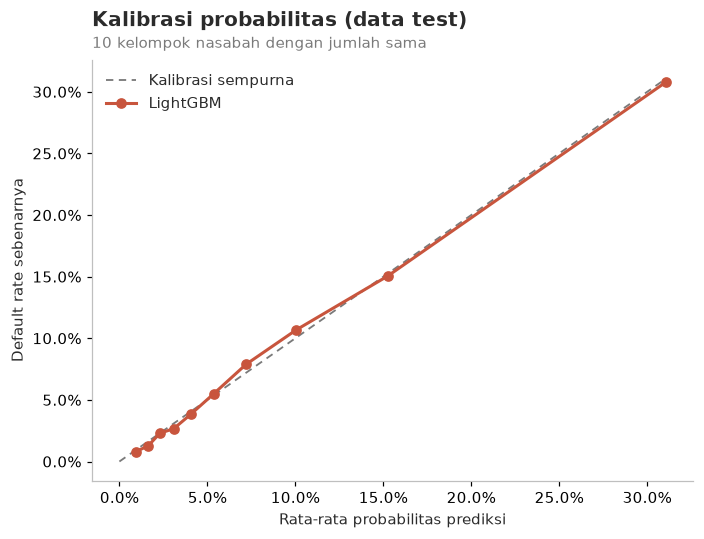

In [33]:
seg = []
for k in X_test['NAME_CONTRACT_TYPE'].unique():
    m = (X_test['NAME_CONTRACT_TYPE'] == k).values
    seg.append({'jenis_kontrak': k, 'jumlah': m.sum(), 'default_rate_%': y_test[m].mean() * 100,
                'PR-AUC': average_precision_score(y_test[m], p_test[m]), 'ROC-AUC': roc_auc_score(y_test[m], p_test[m]),
                'F2': fbeta_score(y_test[m], pred_test[m], beta=2), 'recall': recall_score(y_test[m], pred_test[m])})
display(pd.DataFrame(seg).round(3))
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([0, mean_pred.max()], [0, mean_pred.max()], color=MUTED, ls=(0, (4, 3)), lw=1.2, label='Kalibrasi sempurna')
ax.plot(mean_pred, frac_pos, marker='o', color=MODEL_COLORS.get(BEST, NAVY), lw=2, label=BEST)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel('Rata-rata probabilitas prediksi'); ax.set_ylabel('Default rate sebenarnya'); ax.legend()
ax.set_title('Kalibrasi probabilitas (data test)'); subtitle(ax, '10 kelompok nasabah dengan jumlah sama'); finish()

**Cara membaca:** tabel mengecek performa di segmen *cash loans* (99% data `application_test`, temuan drift NB 03). Grafik kalibrasi: jika titik menempel garis putus-putus, probabilitas model bisa dibaca apa adanya.

**Hasil:**
- **Cash loans** (99% data `application_test`): PR-AUC ±0,295, ROC-AUC ±0,79, recall ±59%. Model bekerja **paling baik** justru di segmen yang paling penting.
- **Revolving loans**: PR-AUC ±0,19, recall ±37%. Lebih lemah karena datanya sedikit (±6.000) dan default rate-nya lebih rendah. Untuk produk revolving, disarankan **monitoring terpisah** atau model khusus di tahap berikutnya.
- **Kalibrasi:** titik-titik mengikuti garis diagonal dengan baik (Brier ±0,066), sehingga probabilitas model dapat langsung dipakai untuk menghitung expected loss per nasabah. Ini keuntungan dari keputusan tanpa class weight.

## 15. Dampak Bisnis (Data Test)

Sesuai NB 01 Bagian 11: biaya gagal bayar yang lolos = pinjaman × LGD (**expected loss**); biaya nasabah baik yang ditolak = pinjaman/2 × margin 13,6% × tenor.

In [34]:
cost_fp_te = business_costs(X_test)[1]; yv = y_test.values
def policy(reject, lgd=LGD):
    cfn = X_test['AMT_CREDIT'].values * lgd
    loss = cfn[(~reject) & (yv == 1)].sum(); opp = cost_fp_te[reject & (yv == 0)].sum()
    return {'disetujui_%': (~reject).mean() * 100, 'default_rate_disetujui_%': yv[~reject].mean() * 100,
            'gagal_bayar_dicegah': int((reject & (yv == 1)).sum()), 'nasabah_baik_ditolak': int((reject & (yv == 0)).sum()),
            'expected_loss': loss, 'keuntungan_hilang': opp, 'total_biaya': loss + opp}
none = np.zeros(len(yv), bool)
ext_rule = (X_test['EXT_SOURCE_MEAN'].fillna(X_test['EXT_SOURCE_MEAN'].median()) < X_train['EXT_SOURCE_MEAN'].quantile(0.10)).values
POL = {'Sebelum (setujui semua)': none, 'Aturan skor eksternal (NB 03)': ext_rule,
       f'Model, F2 murni ({t_f2:.3f})': p_test >= t_f2, f'Model, terpilih ({THRESHOLD:.3f})': p_test >= THRESHOLD,
       f'Model, biaya minimum ({t_cost:.3f})': p_test >= t_cost}
impact = pd.DataFrame({k: policy(v) for k, v in POL.items()}).T
base = impact.iloc[0]
impact['expected_loss_turun_%'] = (1 - impact.expected_loss / base.expected_loss) * 100
impact['hemat_total_%'] = (1 - impact.total_biaya / base.total_biaya) * 100
impact.round(2)

,disetujui_%,default_rate_disetujui_%,gagal_bayar_dicegah,nasabah_baik_ditolak,expected_loss,keuntungan_hilang,total_biaya,expected_loss_turun_%,hemat_total_%
Sebelum (setujui semua),100.00,8.07,0.0,0.0,1.241035e+09,0.000000e+00,1.241035e+09,0.00,0.00
Aturan skor eksternal (NB 03),90.14,6.34,1448.0,4615.0,9.233599e+08,2.982052e+08,1.221565e+09,25.60,1.57
"Model, F2 murni (0.090)",72.08,3.61,3365.0,13808.0,4.416138e+08,1.007373e+09,1.448987e+09,64.42,-16.76
"Model, terpilih (0.120)",79.82,4.34,2833.0,9579.0,5.748884e+08,6.690029e+08,1.243891e+09,53.68,-0.23
"Model, biaya minimum (0.220)",91.98,5.85,1655.0,3276.0,8.678504e+08,2.028302e+08,1.070681e+09,30.07,13.73


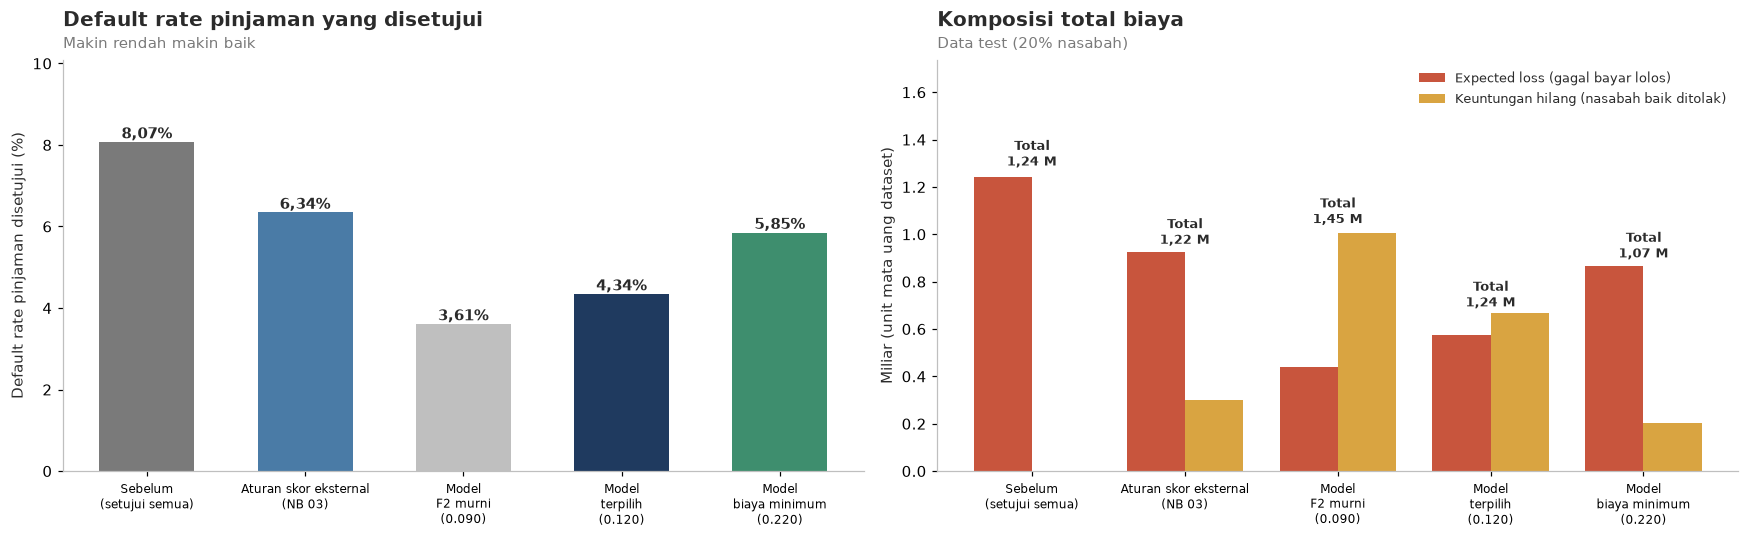

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
names = impact.index.tolist(); n = len(names); cols = [MUTED, BLUE, '#BFBFBF', NAVY, GREEN]
xl = [k.replace(', ', '\n').replace(' (', '\n(') for k in names]
ax = axes[0]
b = ax.bar(range(n), impact['default_rate_disetujui_%'], color=cols, width=0.6)
for bb, v in zip(b, impact['default_rate_disetujui_%']): ax.text(bb.get_x() + bb.get_width()/2, v, f'{fmt(v, 2)}%', ha='center', va='bottom', fontweight='bold')
ax.set_xticks(range(n)); ax.set_xticklabels(xl, fontsize=8); ax.set_ylabel('Default rate pinjaman disetujui (%)')
ax.set_ylim(0, impact['default_rate_disetujui_%'].max() * 1.25); ax.set_title('Default rate pinjaman yang disetujui'); subtitle(ax, 'Makin rendah makin baik')
ax = axes[1]; x = np.arange(n); w = 0.38
ax.bar(x - w/2, impact.expected_loss / 1e9, w, color=RED, label='Expected loss (gagal bayar lolos)')
ax.bar(x + w/2, impact.keuntungan_hilang / 1e9, w, color=ORANGE, label='Keuntungan hilang (nasabah baik ditolak)')
for i, tot in enumerate(impact.total_biaya / 1e9):
    ax.text(i, max(impact.expected_loss.iloc[i], impact.keuntungan_hilang.iloc[i]) / 1e9 * 1.04, f'Total\n{fmt(tot, 2)} M', ha='center', fontsize=8.5, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(xl, fontsize=8); ax.set_ylabel('Miliar (unit mata uang dataset)'); ax.legend(fontsize=8.5, loc='upper right')
ax.set_ylim(0, max(impact.expected_loss.max(), impact.keuntungan_hilang.max()) / 1e9 * 1.4)
ax.set_title('Komposisi total biaya'); subtitle(ax, 'Data test (20% nasabah)'); finish()

**Cara membaca:** kiri = persentase gagal bayar di antara pinjaman yang disetujui. Kanan: merah = **expected loss** (uang hilang karena gagal bayar lolos), oranye = keuntungan hilang karena nasabah baik ditolak. Kebijakan terbaik = total kedua batang paling kecil.

**Hasil (data test, LGD 45%):**

| Kebijakan | Disetujui | Default rate disetujui | Expected loss turun | Total biaya |
|---|---|---|---|---|
| Sebelum (setujui semua) | 100% | 8,07% | - | baseline |
| Aturan skor eksternal (NB 03) | 90% | 6,4% | ±25% | hemat ±1% |
| Model, F2 murni | ±72% | ±3,7% | ±64% | **naik ±16%** |
| **Model, terpilih** | **±80%** | **±4,4%** | **±53%** | **impas** |
| Model, biaya minimum | ±92% | ±5,9% | ±30% | hemat ±13% |

**Interpretasi:**
- Dengan threshold terpilih, **default rate pinjaman yang disetujui turun hampir separuh** (8,1% menjadi ±4,4%) dan **expected loss turun ±53%**, sambil tetap menyetujui ±80% pengajuan.
- Model **jauh lebih baik dari aturan skor eksternal**: expected loss turun ±53% vs ±25% (2× lebih efektif).
- Keuntungan yang hilang dari nasabah baik yang ditolak membuat total biaya impas pada LGD 45%. Pada LGD yang lebih realistis untuk kredit konsumen tanpa jaminan (60-75%), threshold terpilih menghemat **±13-21%** (Bagian 15.1).
- Bila manajemen memprioritaskan profit jangka pendek, threshold biaya minimum memberi penghematan ±13% di semua skenario LGD, dengan konsekuensi expected loss hanya turun ±30%.

### 15.0 Dampak dalam nominal uang

Persentase saja tidak cukup untuk manajemen. jadi dampak juga dihitung dalam **nominal** (unit mata uang dataset; M = miliar. jt = juta). Data test berisi 61.503 pemohon (20% data historis).

In [ ]:
def rp(v):                                             # format nominal: M = miliar, jt = juta (unit mata uang dataset)
    return f'{v/1e9:,.2f} M'.replace(',', '#').replace('.', ',').replace('#', '.') if abs(v) >= 1e9 else \
           f'{v/1e6:,.1f} jt'.replace(',', '#').replace('.', ',').replace('#', '.')
b0 = impact.iloc[0]
nominal = pd.DataFrame({
    'Expected loss': impact.expected_loss.map(rp),
    'Expected loss dicegah': (b0.expected_loss - impact.expected_loss).map(rp),
    'Keuntungan hilang': impact.keuntungan_hilang.map(rp),
    'Total biaya': impact.total_biaya.map(rp),
    'Penghematan bersih': (b0.total_biaya - impact.total_biaya).map(lambda v: ('+' if v >= 0 else '-') + rp(abs(v))),
    'Penghematan per 1.000 pemohon': ((b0.total_biaya - impact.total_biaya) / len(y_test) * 1000).map(lambda v: f'{v:,.0f}'.replace(',', '.')),
})
nominal

,Expected loss,Expected loss dicegah,Keuntungan hilang,Total biaya,Penghematan bersih,Penghematan per 1.000 pemohon
kebijakan,,,,,,
Sebelum (setujui semua),"1,24 M","0,0 jt","0,0 jt","1,24 M","+0,0 jt",0
Aturan skor eksternal (NB 03),"923,4 jt","317,7 jt","298,2 jt","1,22 M","+19,5 jt",316.562
"Model, F2 murni (0.090)","441,6 jt","799,4 jt","1,01 M","1,45 M","-208,0 jt",-3.381.175
"Model, terpilih (0.120)","574,9 jt","666,1 jt","669,0 jt","1,24 M","-2,9 jt",-46.449
"Model, biaya minimum (0.220)","867,9 jt","373,2 jt","202,8 jt","1,07 M","+170,4 jt",2.769.849


**Cara membaca tabel nominal:**
- **Expected loss** = total pinjaman gagal bayar yang tetap disetujui × LGD 45%. Tanpa model nilainya **1,24 M**.
- Dengan threshold terpilih, expected loss menjadi **574,9 jt**: kerugian yang dicegah **666,1 jt**.
- Harga yang dibayar: **669,0 jt** margin hilang karena 9.579 nasabah baik ikut ditolak. Pada LGD 45% keduanya hampir seimbang (penghematan bersih -2,9 jt).
- Skala portofolio penuh kira-kira 5× angka di atas (data test = 20%). Pada LGD 60-75%, penghematan bersih threshold terpilih menjadi 13-21% dari total biaya (Bagian 15.1).

### 15.1 Uji sensitivitas LGD

In [36]:
sens = []
for lgd in [0.45, 0.60, 0.75]:
    a = policy(none, lgd)
    for lbl, rej in [('terpilih', p_test >= THRESHOLD), ('biaya minimum', p_test >= t_cost)]:
        bb = policy(rej, lgd)
        sens.append({'LGD': f'{int(lgd*100)}%', 'threshold': lbl, 'expected_loss_turun_%': (1 - bb['expected_loss'] / a['expected_loss']) * 100,
                     'hemat_total_%': (1 - bb['total_biaya'] / a['total_biaya']) * 100})
pd.DataFrame(sens).round(1)

,LGD,threshold,expected_loss_turun_%,hemat_total_%
0,45%,terpilih,53.7,-0.2
1,45%,biaya minimum,30.1,13.7
2,60%,terpilih,53.7,13.2
3,60%,biaya minimum,30.1,17.8
4,75%,terpilih,53.7,21.3
5,75%,biaya minimum,30.1,20.3


**Cara membaca:** LGD tidak dipublikasikan Home Credit, sehingga diuji 3 skenario (NB 01). Jika model tetap menguntungkan di semua skenario, kesimpulannya tidak bergantung pada asumsi.

### 15.2 Simulasi kebijakan 3 zona

- Probabilitas < threshold terpilih: **Approve**
- Antara threshold terpilih dan threshold biaya minimum: **Review / limit dikurangi** (NB 03: kelola risikonya, bukan langsung tolak)
- ≥ threshold biaya minimum: **Reject**

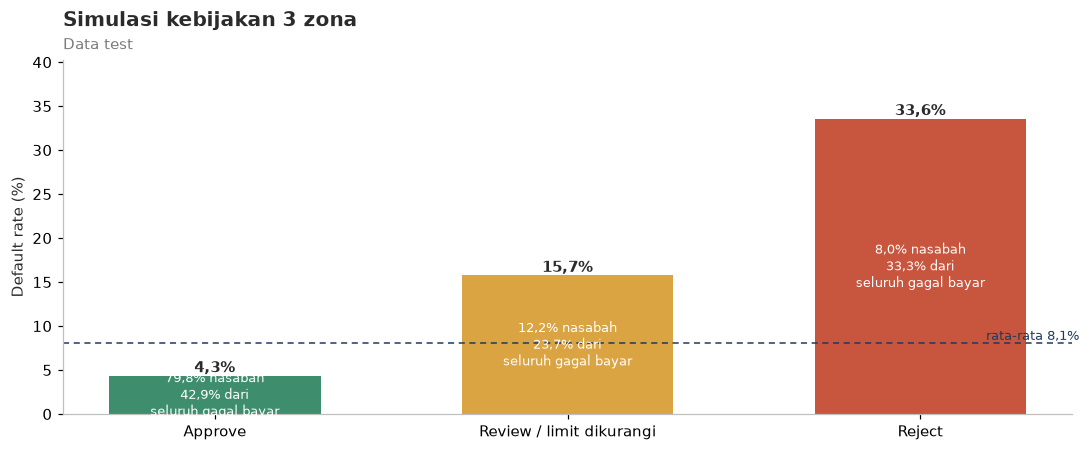

,jumlah,porsi_%,default_rate_%,porsi_seluruh_gagal_bayar_%
zona,,,,
Approve,49091,79.82,4.34,42.94
Review / limit dikurangi,7481,12.16,15.75,23.73
Reject,4931,8.02,33.56,33.33


In [37]:
zones = pd.cut(p_test, [0, THRESHOLD, T_REJECT + 1e-9, 1.0001], labels=['Approve', 'Review / limit dikurangi', 'Reject'], include_lowest=True, right=False)
zdf = pd.DataFrame({'zona': zones, 'y': yv})
zt = zdf.groupby('zona', observed=False).y.agg(jumlah='count', default_rate='mean')
zt['porsi_%'] = zt.jumlah / len(yv) * 100; zt['default_rate_%'] = zt.default_rate * 100
zt['porsi_seluruh_gagal_bayar_%'] = zdf.groupby('zona', observed=False).y.sum() / yv.sum() * 100
zt = zt.drop(columns='default_rate')
fig, ax = plt.subplots(figsize=(10, 4.2))
b = ax.bar(zt.index.astype(str), zt['default_rate_%'], color=[GREEN, ORANGE, RED], width=0.6)
for bb, v, s, g in zip(b, zt['default_rate_%'], zt['porsi_%'], zt['porsi_seluruh_gagal_bayar_%']):
    ax.text(bb.get_x() + bb.get_width()/2, v, f'{fmt(v)}%', ha='center', va='bottom', fontweight='bold')
    if v > 3: ax.text(bb.get_x() + bb.get_width()/2, v / 2, f'{fmt(s)}% nasabah\n{fmt(g)}% dari\nseluruh gagal bayar', ha='center', va='center', color='white', fontsize=8.5)
ax.axhline(y_test.mean() * 100, color=NAVY, ls=(0, (4, 3)), lw=1); ax.text(2.45, y_test.mean() * 100, f'rata-rata {fmt(y_test.mean()*100)}%', color=NAVY, ha='right', va='bottom', fontsize=8.5)
ax.set_ylabel('Default rate (%)'); ax.set_ylim(0, zt['default_rate_%'].max() * 1.2)
ax.set_title('Simulasi kebijakan 3 zona'); subtitle(ax, 'Data test'); finish()
zt.round(2)

**Cara membaca:** tinggi batang = default rate tiap zona; teks putih = porsi nasabah dan porsi dari seluruh gagal bayar di zona tersebut.

**Hasil (data test):**

| Zona | Porsi pemohon | Default rate | Porsi dari seluruh gagal bayar |
|---|---|---|---|
| **Approve** | ±80% | ±4,4% (separuh rata-rata) | ±43% |
| **Review / limit dikurangi** | ±12% | ±16% (2× rata-rata) | ±23% |
| **Reject** | ±8% | ±33% (4× rata-rata) | ±33% |

**Interpretasi & rekomendasi:**
- **Zona Reject hanya 8% pemohon tetapi berisi 1/3 seluruh gagal bayar**; 1 dari 3 pemohon di zona ini gagal bayar.
- **Zona Review (12%)** memuat 23% gagal bayar. Di sini analis kredit bekerja: verifikasi dokumen, limit lebih kecil, atau uang muka lebih besar (sesuai rekomendasi NB 03), alih-alih langsung menolak.
- **Zona Approve (80%)** bisa diproses dengan **jalur cepat** karena default rate-nya hanya setengah rata-rata portofolio. Dengan begitu, beban analis cukup fokus pada **20% pengajuan** yang berisi **56% risiko**.

### 15.3 Kenapa threshold terpilih, bukan F2 tertinggi atau biaya minimum?

| Pilihan | Recall | Expected loss (merah) | Keuntungan hilang (oranye) | Total biaya | Masalah |
|---|---|---|---|---|---|
| F2 tertinggi (0.090) | tertinggi | 441,6 jt (paling kecil) | 1,01 M | 1,45 M | Total biaya **naik 17%** dibanding tanpa model |
| **Terpilih (0.120)** | ±57% | 574,9 jt | 669,0 jt | 1,24 M | Impas di LGD 45%, hemat di LGD 60-75% |
| Biaya minimum (0.220) | ±32% | 867,9 jt | 202,8 jt | 1,07 M (paling kecil) | 2 dari 3 calon gagal bayar tetap lolos |

- **Kenapa tidak F2 tertinggi (merah paling kecil)?** F2 hanya menghitung *jumlah* kasus, bukan *nilai uang*. Di titik F2 tertinggi model menolak 13.808 nasabah baik; margin yang hilang (1,01 M) lebih besar daripada kerugian yang dicegah. Menekan merah sampai minimum justru membuat oranye membengkak.
- **Kenapa tidak biaya minimum (total paling kecil)?** Total biaya memang terkecil, tetapi recall hanya ±32%. Tujuan bisnis di NB 01 adalah menangkap sebanyak mungkin calon gagal bayar (F2), dan risiko reputasi serta beban penagihan dari kredit macet tidak masuk ke rumus biaya ini.
- **Jalan tengah: kebijakan 3 zona (Bagian 15.2).** Threshold terpilih menjadi batas **Approve** (recall tetap tinggi), threshold biaya minimum menjadi batas **Reject**. Pemohon di antaranya (±12%) masuk **Review**: limit dikurangi atau minta uang muka, bukan langsung ditolak. Dengan begitu sebagian margin (oranye) tetap didapat, sementara risikonya (merah) diperkecil. Efek nominal skenario potong limit dapat disimulasikan di aplikasi Streamlit, halaman *Performa & Kebijakan*.

## 16. Interpretasi Model dengan SHAP

SHAP (Lundberg & Lee, 2017) menghitung **seberapa besar setiap fitur menaikkan atau menurunkan skor risiko** setiap nasabah. Dihitung pada 5.000 nasabah sampel dari data test.

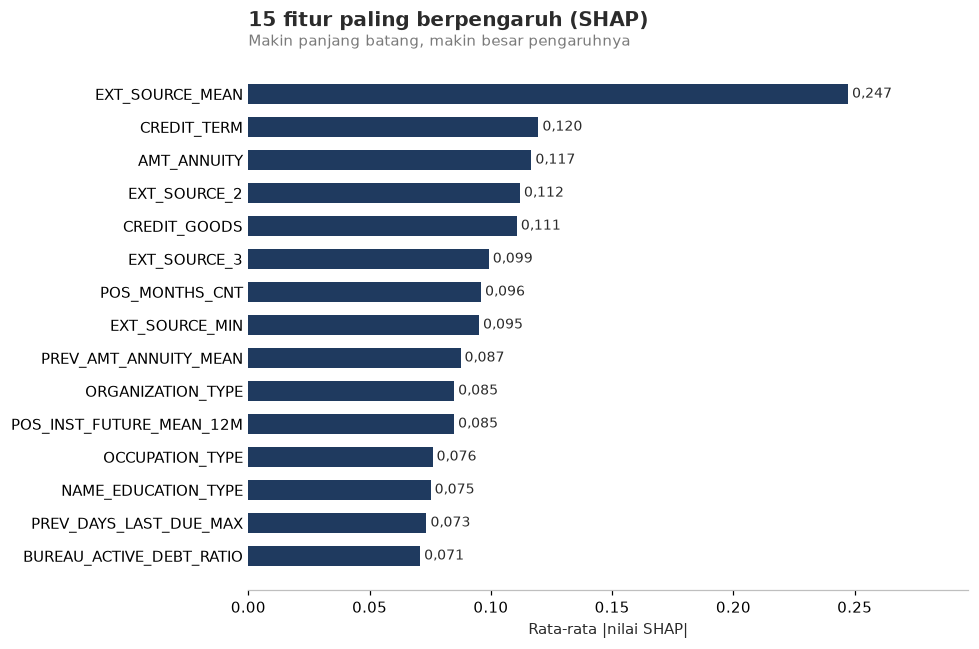

In [38]:
N_SHAP = 5000
shap_sample = X_test.sample(N_SHAP, random_state=SEED)
explain_pipe = final_model.named_estimators_['lgbm'] if BEST == 'Ensemble' else final_model
prep, mdl = explain_pipe[:-1], explain_pipe[-1]
clean_name = lambda n: n.split('__', 1)[1] if '__' in n else n
names = [clean_name(n) for n in explain_pipe.named_steps['prep'].get_feature_names_out()]
shap_X = pd.DataFrame(np.asarray(prep.transform(shap_sample), dtype=float), columns=names, index=shap_sample.index)
if isinstance(mdl, LogisticRegression):
    bg = pd.DataFrame(np.asarray(prep.transform(X_train.sample(2000, random_state=SEED)), dtype=float), columns=names)
    sv = shap.LinearExplainer(mdl, bg)(shap_X)
else:
    sv = shap.TreeExplainer(mdl)(shap_X)
if sv.values.ndim == 3: sv = sv[:, :, 1]

imp = pd.Series(np.abs(sv.values).mean(axis=0), index=names).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp.values, color=NAVY, height=0.62)
for i, v in enumerate(imp.values): ax.text(v, i, f' {fmt(v, 3)}', va='center', fontsize=9)
ax.set_xlabel('Rata-rata |nilai SHAP|'); ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_xlim(0, imp.max() * 1.2); ax.set_title('15 fitur paling berpengaruh (SHAP)'); subtitle(ax, 'Makin panjang batang, makin besar pengaruhnya')
finish()

**Cara membaca:** panjang batang = rata-rata besarnya pengaruh fitur terhadap skor risiko (tanpa melihat arah).

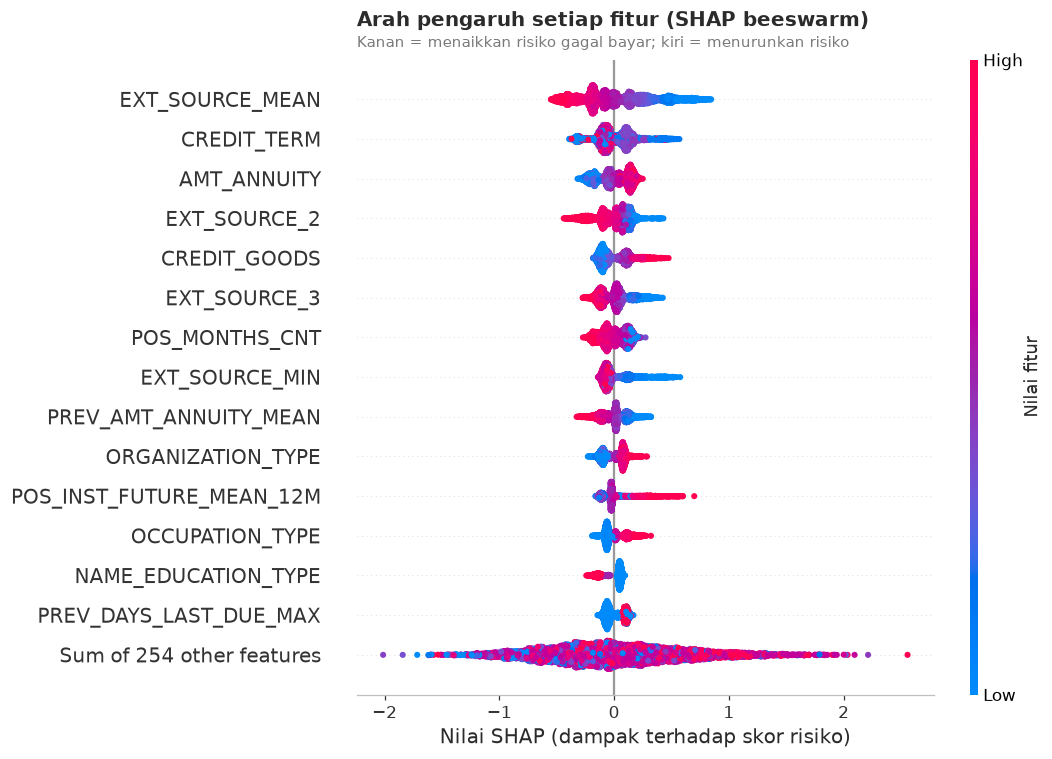

In [39]:
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False, color_bar_label='Nilai fitur')
ax = plt.gca(); ax.set_title('Arah pengaruh setiap fitur (SHAP beeswarm)', loc='left', fontweight='bold', pad=22)
ax.text(0, 1.02, 'Kanan = menaikkan risiko gagal bayar; kiri = menurunkan risiko', transform=ax.transAxes, fontsize=9.5, color=MUTED)
ax.set_xlabel('Nilai SHAP (dampak terhadap skor risiko)'); plt.gcf().set_size_inches(10, 7); plt.tight_layout(); plt.show()

**Cara membaca beeswarm:** setiap titik = satu nasabah. Posisi horizontal = pengaruh fitur terhadap skor risikonya (kanan = menaikkan). Warna = nilai fitur (merah tinggi, biru rendah). Contoh: titik biru di kanan berarti **nilai rendah** fitur itu **menaikkan** risiko.

**Hasil (sejalan dengan EDA NB 03):**
1. **`EXT_SOURCE_MEAN`** paling berpengaruh: skor rendah (biru) menaikkan risiko, skor tinggi (merah) menurunkannya. Konsisten dengan NB 03 Q1-Q2.
2. **`CREDIT_TERM`** (perkiraan tenor = pinjaman/cicilan) dan **`AMT_ANNUITY`**: struktur cicilan sangat menentukan risiko. Hubungannya **tidak linear** (lihat dependence plot).
3. **`CREDIT_GOODS`**: pinjaman yang melebihi harga barang menaikkan risiko (merah di kanan), konsisten dengan NB 03 Q6 (uang muka = risiko lebih rendah).
4. **Fitur riwayat v2** (`POS_INST_FUTURE_MEAN_12M`, `POS_MONTHS_CNT`, `PREV_AMT_ANNUITY_MEAN`, `INST_CNT`) masuk 15 besar. Ini membuktikan manfaat data mart versi 2: **sisa cicilan yang masih banyak di pinjaman lain** menaikkan risiko.
5. **`ORGANIZATION_TYPE`** dan **`OCCUPATION_TYPE`** (hasil target encoding) masuk 15 besar, konsisten dengan NB 03 Q8.
6. **`AGE_YEARS`** berpengaruh, tetapi jauh di bawah skor eksternal, sejalan dengan NB 03 Q4 (usia bukan penentu utama).

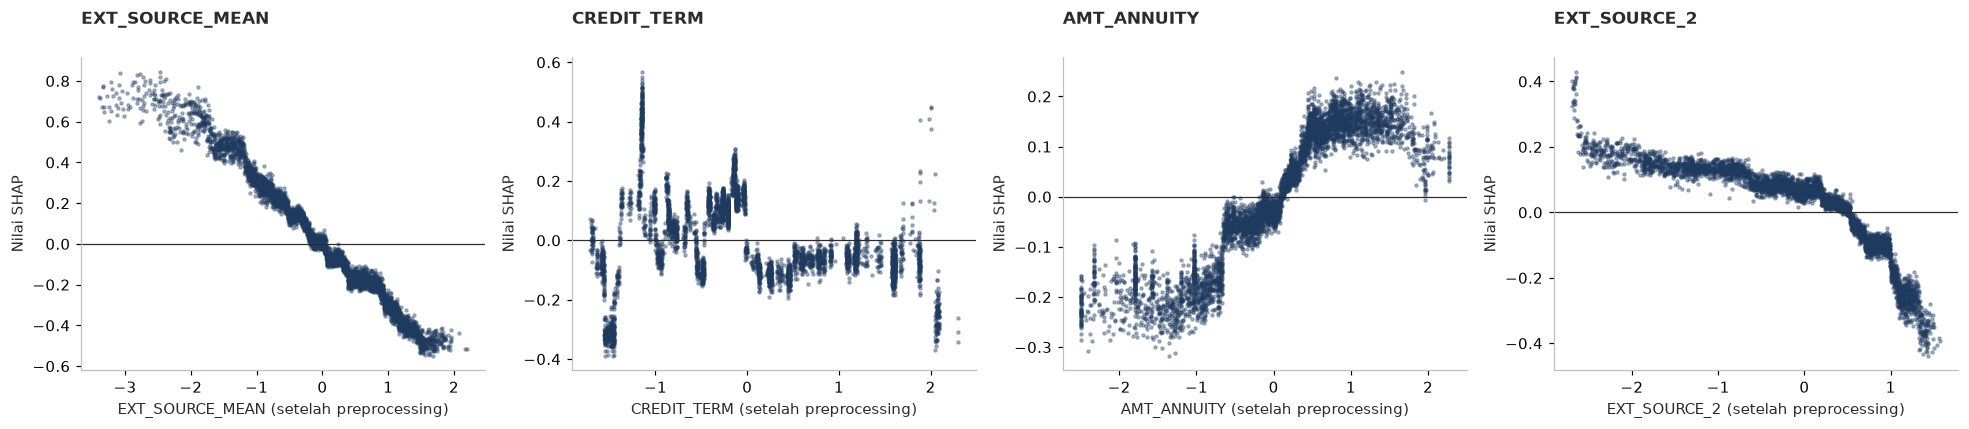

In [40]:
top4 = imp.index[::-1][:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, top4):
    ax.scatter(shap_X[f], sv[:, f].values, s=4, alpha=0.35, color=NAVY); ax.axhline(0, color=INK, lw=0.8)
    ax.set_xlabel(f'{f} (setelah preprocessing)'); ax.set_ylabel('Nilai SHAP'); ax.set_title(f, fontsize=11)
finish()

**Cara membaca dependence plot:** sumbu mendatar = nilai fitur (sudah diskalakan oleh pipeline), sumbu tegak = pengaruhnya. Titik di atas garis nol = menaikkan risiko.

**Hasil:**
- **`EXT_SOURCE_MEAN`:** hubungan **menurun hampir lurus**. Makin tinggi skor, makin rendah risiko, tanpa titik jenuh.
- **`CREDIT_TERM`:** **tidak monoton**. Ada tenor tertentu yang jauh lebih berisiko daripada tenor di sekitarnya, kemungkinan karena produk atau skema cicilan tertentu. Pola seperti ini tidak dapat ditangkap aturan sederhana maupun Logistic Regression, dan menjadi salah satu alasan LightGBM unggul.
- **`CREDIT_GOODS`:** **naik bertahap**. Makin besar pinjaman dibanding harga barang, makin tinggi risikonya. Ini mendukung rekomendasi **insentif uang muka** di NB 03.
- **`EXT_SOURCE_2`:** pengaruh terbesar ada di **nilai sangat rendah**. Di atas rata-rata, efeknya mulai mendatar.

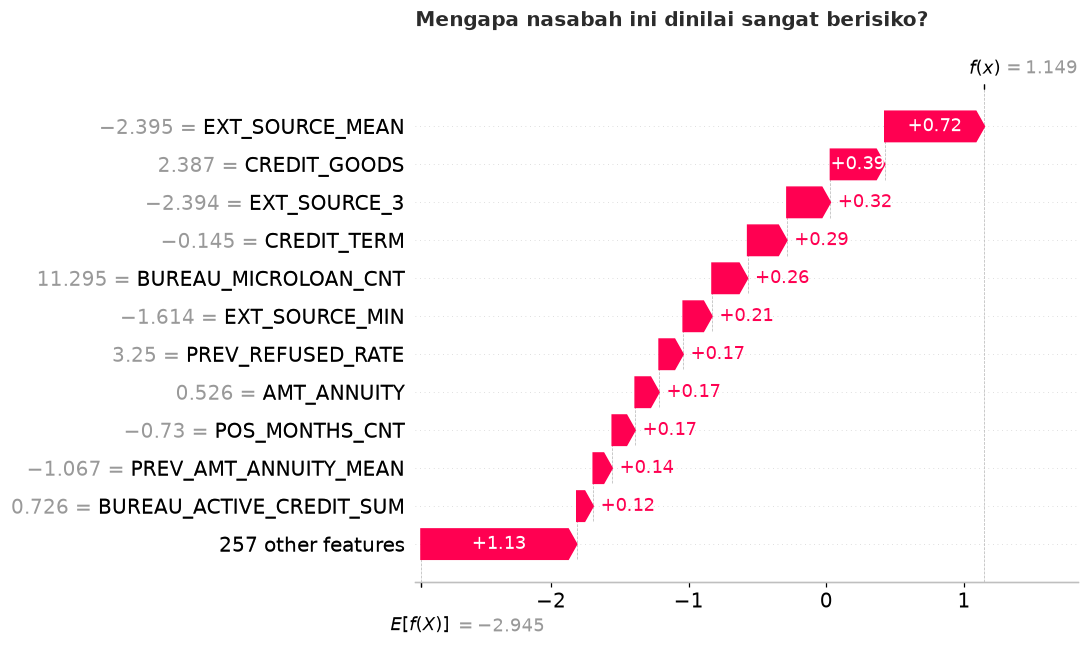

In [41]:
idx_hi = int(np.argmax(final_model.predict_proba(shap_sample)[:, 1]))
plt.figure(); shap.plots.waterfall(sv[idx_hi], max_display=12, show=False)
plt.gcf().set_size_inches(10, 6); plt.title('Mengapa nasabah ini dinilai sangat berisiko?', loc='left', fontweight='bold'); plt.tight_layout(); plt.show()

**Cara membaca waterfall:** dimulai dari skor rata-rata (bawah, `E[f(x)]`); setiap batang merah menaikkan dan biru menurunkan skor, hingga skor akhir nasabah ini (atas, `f(x)`). Penjelasan ini bisa diberikan ke analis kredit untuk setiap keputusan, dan akan ditampilkan di aplikasi Streamlit.

## 17. Uji Keadilan: Dengan vs Tanpa Gender

Gender dikeluarkan sesuai prinsip perlakuan adil dan non-diskriminatif (POJK 22/2023). Pertanyaannya: **berapa performa yang "dikorbankan"?** Diuji dengan LightGBM ber-parameter terbaik.

In [42]:
feats_g = FEATURES + ['CODE_GENDER']; groups_g = column_groups(X_train[feats_g])
pipe_g = make_pipe(BASE_MODELS['LightGBM'](CW['LightGBM']), features=feats_g, groups=groups_g).set_params(**tuned['LightGBM'])
p_g, _ = oof(pipe_g)
pd.DataFrame([evaluate(y_train, oof_preds['LightGBM'], 'LightGBM tanpa gender'), evaluate(y_train, p_g, 'LightGBM dengan gender')]).set_index('model')[['PR-AUC', 'ROC-AUC', 'F2']].round(4)

,PR-AUC,ROC-AUC,F2
model,,,
LightGBM tanpa gender,0.2797,0.7883,0.4539
LightGBM dengan gender,0.2812,0.7892,0.4545


**Hasil:** menambahkan gender hanya menaikkan PR-AUC sebesar **±0,002** (0,281 menjadi 0,283) dan F2 sebesar ±0,002.

**Keputusan:** gender **tetap dikeluarkan**. Kenaikan performanya sangat kecil (di bawah variasi antar fold), sedangkan risikonya besar: diskriminasi terhadap konsumen bertentangan dengan prinsip perlindungan konsumen (POJK 22/2023) dan dapat merusak reputasi. Informasi yang relevan secara bisnis (pekerjaan, pendapatan, perilaku bayar) sudah tertangkap oleh fitur lain.

## 18. Simpan Model, Artefak Evaluasi & Prediksi `application_test`

Selain model, hasil evaluasi (kurva PR, kurva threshold, dampak bisnis, SHAP) disimpan ke `models/eval_artifacts.json` agar aplikasi Streamlit dapat menampilkannya tanpa melatih ulang model.

In [43]:
def _thin(a, n=300):
    a = np.asarray(a); idx = np.linspace(0, len(a) - 1, min(n, len(a))).astype(int); return a[idx].tolist()
prec_t, rec_t, _ = precision_recall_curve(y_test, p_test); fpr_t, tpr_t, _ = roc_curve(y_test, p_test)
artifacts = {
    'best_model': BEST, 'threshold_approve': THRESHOLD, 'threshold_reject': T_REJECT, 'threshold_f2_max': float(t_f2),
    'metrics': res.reset_index().to_dict(orient='records'),
    'compare_oof': compare.reset_index().to_dict(orient='records'),
    'class_weight': {k: (v or 'Tanpa') for k, v in CW.items()},
    'pr_curve_test': {'recall': _thin(rec_t), 'precision': _thin(prec_t), 'base_rate': float(y_test.mean())},
    'roc_curve_test': {'fpr': _thin(fpr_t), 'tpr': _thin(tpr_t)},
    'threshold_curve': curve.to_dict(orient='list'),
    'impact': impact.reset_index().rename(columns={'index': 'kebijakan'}).to_dict(orient='records'),
    'zones': zt.reset_index().astype({'zona': str}).to_dict(orient='records'),
    'confusion_matrix': cm.tolist(),
    'shap_importance': imp[::-1].to_dict(),
    'segment_contract': pd.DataFrame(seg).to_dict(orient='records')}
json.dump(artifacts, open(MODEL_DIR / 'eval_artifacts.json', 'w'), indent=1, default=float)
print('Artefak evaluasi disimpan:', MODEL_DIR / 'eval_artifacts.json')

Artefak evaluasi disimpan: models\eval_artifacts.json


## 18.1 Simpan model final

In [44]:
final_model_full = final_pipes[BEST].fit(X_all, y_all)          # dilatih ulang dengan seluruh data berlabel
joblib.dump(final_model_full, MODEL_DIR / 'credit_risk_model.joblib')
meta = {'model': BEST, 'threshold_approve': THRESHOLD, 'threshold_reject': T_REJECT, 'features': FEATURES, 'groups': GROUPS,
        'LGD': LGD, 'NIM': NIM, 'seed': SEED, 'cv_pr_auc': float(compare.loc[BEST, 'PR-AUC']),
        'test_pr_auc': float(res['PR-AUC'].iloc[1]), 'test_roc_auc': float(res['ROC-AUC'].iloc[1]), 'test_f2': float(res['F2'].iloc[1])}
json.dump(meta, open(MODEL_DIR / 'model_metadata.json', 'w'), indent=2)
sub = pd.DataFrame({'SK_ID_CURR': test_raw['SK_ID_CURR'].astype(int), 'TARGET': final_model_full.predict_proba(kaggle_test)[:, 1]})
sub.to_csv('submission.csv', index=False)
print(f'Model: {MODEL_DIR / "credit_risk_model.joblib"} | Prediksi application_test: {len(sub):,} nasabah -> submission.csv')

Model: models\credit_risk_model.joblib | Prediksi application_test: 48,744 nasabah -> submission.csv


**Catatan:** model final dilatih ulang dengan seluruh data berlabel memakai parameter dan threshold yang sudah dikunci. Estimasi performanya tetap memakai hasil test di Bagian 14.

## 19. Kesimpulan & Rekomendasi

### Model final
| Aspek | Hasil |
|---|---|
| Model | **LightGBM** (tanpa class weight, parameter hasil tuning dengan regularisasi kuat) |
| Fitur | 142 fitur: data aplikasi + riwayat kredit versi 2 + 17 fitur turunan berbasis temuan EDA (gender dikeluarkan) |
| Preprocessing | 1 pipeline: median + penanda kosong, winsorizing, log/robust/standard scaling sesuai distribusi, one-hot / target encoding / ordinal sesuai kardinalitas |
| Performa test | PR-AUC ±0,29 (model acak 0,08), ROC-AUC ±0,79, Gini ±0,58, F2 ±0,44, stabil antara CV dan test |
| Threshold | ±0,12 (F2 maksimum dengan guardrail biaya) + ±0,215 untuk zona Reject |

### Apakah performa ini sudah maksimal?
Sudah diuji dari berbagai arah: data mart diperkaya (+0,010), tuning luas termasuk parameter preprocessing (+0,004), class weight (tidak membantu), fitur turunan tambahan (+0,001), seleksi fitur (justru turun), ensemble (+0,001), dan menambahkan gender (+0,002). Semua jalur memberi kenaikan **kecil dan mengecil**, tanda bahwa model sudah mendekati **batas informasi di data**. Sebagai pembanding, tim peringkat atas kompetisi resmi dataset ini mencapai ROC-AUC ±0,80 dengan ratusan fitur dan gabungan banyak model; model ini mencapai ±0,79 dengan satu model yang dapat dijelaskan.

### Dampak bisnis (data test)
- **Default rate pinjaman yang disetujui turun dari 8,1% menjadi ±4,4%.**
- **Expected loss turun ±53%**, 2× lebih efektif daripada aturan skor eksternal terbaik.
- Total biaya impas pada LGD 45% (paling konservatif), dan **hemat ±13-21%** pada LGD 60-75%.
- **Kebijakan 3 zona**: 80% pengajuan dapat diproses jalur cepat; analis cukup fokus pada 20% pengajuan yang berisi 56% risiko.

### Rekomendasi untuk Credit Risk
1. **Terapkan kebijakan 3 zona** berbasis skor model: Approve (jalur cepat), Review (limit / uang muka disesuaikan), Reject.
2. **Prioritaskan verifikasi** pada pemohon dengan skor eksternal rendah, pinjaman di atas harga barang, dan sisa cicilan tinggi di pinjaman lain (3 faktor teratas SHAP).
3. **Insentif uang muka**: rasio pinjaman/harga barang terbukti menaikkan risiko secara bertahap.
4. **Monitoring model**: hitung ulang PR-AUC dan default rate per zona setiap bulan; buat model terpisah untuk produk revolving jika volumenya bertambah.
5. **Lengkapi data LGD aktual** dari divisi penagihan agar perhitungan dampak bisnis (dan threshold) lebih tepat.

## Referensi
1. Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR*, 13, 281-305.
2. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
3. Chen, T., & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *KDD*.
4. Elkan, C. (2001). The foundations of cost-sensitive learning. *IJCAI*.
5. Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5).
6. Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining. *ACM TKDD*, 6(4).
7. Ke, G., et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS*.
8a. Ambroise, C., & McLachlan, G. J. (2002). Selection bias in gene extraction on the basis of microarray gene-expression data. *PNAS*, 99(10), 6562-6566.
8. Kohavi, R. (1995). A study of cross-validation and bootstrap for accuracy estimation and model selection. *IJCAI*.
9. Kuhn, M., & Johnson, K. (2019). *Feature Engineering and Selection*. CRC Press.
10. Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). Wiley.
11. Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS*.
12. Micci-Barreca, D. (2001). A preprocessing scheme for high-cardinality categorical attributes. *ACM SIGKDD Explorations*, 3(1).
13. Otoritas Jasa Keuangan (2023). POJK Nomor 22 Tahun 2023 tentang Pelindungan Konsumen dan Masyarakat di Sektor Jasa Keuangan.
14. Pargent, F., Pfisterer, F., Thomas, J., & Bischl, B. (2022). Regularized target encoding outperforms traditional methods in supervised machine learning with high cardinality features. *Computational Statistics*, 37, 2671-2692.
15. Raschka, S. (2018). Model evaluation, model selection, and algorithm selection in machine learning. *arXiv:1811.12808*.
16. Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3).
17. Siddiqi, N. (2017). *Intelligent Credit Scoring* (2nd ed.). Wiley.
18. van den Goorbergh, R., et al. (2022). The harm of class imbalance corrections for risk prediction models. *JAMIA*, 29(9), 1525-1534.